In [1]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder
from xgboost import XGBClassifier

df = pd.read_csv("AmesHousing.csv", sep="\t", keep_default_na=False,  # pandas turns the strings "NA"/"None" into NaN; here they mean the feature is absent (no pool, no alley), not missing data
    na_values=[""])


def clean_task1(data):
    """Zeilenweise Behandlung fehlender Werte aus Aufgabe 1 (keine Statistik ueber andere Zeilen)."""
    data = data.copy()
    absence_cols = ["Pool QC", "Misc Feature", "Alley", "Fence", "Mas Vnr Type", "Fireplace Qu",
                    "Garage Type", "Garage Finish", "Garage Qual", "Garage Cond",
                    "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2"]
    data[absence_cols] = data[absence_cols].replace("NA", "None").fillna("None")

    # Muss vor der Imputation von Lot Frontage (in der Pipeline) entstehen.
    data["Lot Frontage Missing"] = data["Lot Frontage"].isnull().astype(int)

    # Leer nur dann, wenn Garage/Keller/Verblendung fehlt -> Groesse 0.
    zero_cols = ["Garage Area", "Garage Cars", "BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF",
                 "Total Bsmt SF", "Bsmt Full Bath", "Bsmt Half Bath", "Mas Vnr Area"]
    data[zero_cols] = data[zero_cols].fillna(0)
    data["Garage Yr Blt"] = data["Garage Yr Blt"].fillna(0)

    # MS SubClass ist ein Gebaeudetyp-Code, keine Groesse.
    data["MS SubClass"] = data["MS SubClass"].astype(str)
    return data


df_clean = clean_task1(df)

print(f"Bereinigter Datensatz: {df_clean.shape[0]} Zeilen, {df_clean.shape[1]} Spalten")
print("Noch fehlende Werte (werden in der Pipeline imputiert):")
display(df_clean.isnull().sum()[lambda counts: counts > 0])
display(df_clean.head())

Bereinigter Datensatz: 2930 Zeilen, 83 Spalten
Noch fehlende Werte (werden in der Pipeline imputiert):


Lot Frontage    490
Electrical        1
dtype: int64

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice,Lot Frontage Missing
0,1,526301100,20,RL,141.0,31770,Pave,None,IR1,Lvl,...,None,None,None,0,5,2010,WD,Normal,215000,0
1,2,526350040,20,RH,80.0,11622,Pave,None,Reg,Lvl,...,None,MnPrv,None,0,6,2010,WD,Normal,105000,0
2,3,526351010,20,RL,81.0,14267,Pave,None,IR1,Lvl,...,None,None,Gar2,12500,6,2010,WD,Normal,172000,0
3,4,526353030,20,RL,93.0,11160,Pave,None,Reg,Lvl,...,None,None,None,0,4,2010,WD,Normal,244000,0
4,5,527105010,60,RL,74.0,13830,Pave,None,IR1,Lvl,...,None,MnPrv,None,0,3,2010,WD,Normal,189900,0


In [2]:
class_names = [
    "< 100.000",
    "100.000 - < 130.000",
    "130.000 - < 180.000",
    "180.000 - < 250.000",
    "250.000 - < 400.000",
    ">= 400.000",
]
price_bins = [-np.inf, 100_000, 130_000, 180_000, 250_000, 400_000, np.inf]

y = pd.cut(
    df_clean["SalePrice"],
    bins=price_bins,
    labels=False,
    right=False,
).astype("int64")
X = df_clean.drop(columns=["SalePrice", "Order", "PID"])

class_distribution = y.value_counts().sort_index()
display(
    class_distribution.rename(index=dict(enumerate(class_names)))
    .rename("Anzahl")
    .to_frame()
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)
print(f"Trainingsdaten: {X_train.shape[0]} | Testdaten: {X_test.shape[0]}")

,Anzahl
SalePrice,
< 100.000,237
100.000 - < 130.000,509
130.000 - < 180.000,1037
180.000 - < 250.000,686
250.000 - < 400.000,397
>= 400.000,64


Trainingsdaten: 2344 | Testdaten: 586


In [3]:
display(
    pd.DataFrame({
        "SalePrice": df_clean["SalePrice"],
        "class_id": y,
        "price_class": y.map(dict(enumerate(class_names))),
    }).head(10)
)

,SalePrice,class_id,price_class
0,215000,3,180.000 - < 250.000
1,105000,1,100.000 - < 130.000
2,172000,2,130.000 - < 180.000
3,244000,3,180.000 - < 250.000
4,189900,3,180.000 - < 250.000
5,195500,3,180.000 - < 250.000
6,213500,3,180.000 - < 250.000
7,191500,3,180.000 - < 250.000
8,236500,3,180.000 - < 250.000
9,189000,3,180.000 - < 250.000


In [4]:
class NeighborhoodMedianImputer(BaseEstimator, TransformerMixin):
    """Fuellt Lot Frontage mit dem Median der Nachbarschaft (gelernt auf den Trainingsdaten)."""

    def fit(self, X, y=None):
        self.neighborhood_medians_ = X.groupby("Neighborhood")["Lot Frontage"].median()
        self.global_median_ = X["Lot Frontage"].median()
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        X = X.copy()
        X["Lot Frontage"] = (
            X["Lot Frontage"]
            .fillna(X["Neighborhood"].map(self.neighborhood_medians_))
            .fillna(self.global_median_)
        )
        return X

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_


# Reihenfolge jeweils von schlecht nach gut; "None" = nicht vorhanden.
quality_scale = ["None", "Po", "Fa", "TA", "Gd", "Ex"]
ordinal_categories = {
    "Exter Qual": quality_scale,
    "Exter Cond": quality_scale,
    "Bsmt Qual": quality_scale,
    "Bsmt Cond": quality_scale,
    "Heating QC": quality_scale,
    "Kitchen Qual": quality_scale,
    "Garage Qual": quality_scale,
    "Garage Cond": quality_scale,
    "Fireplace Qu": quality_scale,
    "Pool QC": quality_scale,
    "Bsmt Exposure": ["None", "No", "Mn", "Av", "Gd"],
    "BsmtFin Type 1": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFin Type 2": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "Garage Finish": ["None", "Unf", "RFn", "Fin"],
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "Paved Drive": ["N", "P", "Y"],
    "Land Slope": ["Sev", "Mod", "Gtl"],
    "Lot Shape": ["IR3", "IR2", "IR1", "Reg"],
    "Utilities": ["ELO", "NoSeWa", "NoSewr", "AllPub"],
    "Central Air": ["N", "Y"],
}
ordinal_features = list(ordinal_categories)


def numeric_columns(X):
    return X.select_dtypes(include=["number"]).columns.tolist()


def nominal_columns(X):
    return [
        column
        for column in X.select_dtypes(include=["object", "category", "str"]).columns
        if column not in ordinal_categories
    ]


def text_columns(X):
    return X.select_dtypes(include=["object", "category", "str"]).columns.tolist()


def add_engineered_features(X):
    """Zusaetzliche Merkmale (nur fuer das Experiment zur Datenvorbereitung)."""
    X = X.copy()
    X["Total SF"] = X["Total Bsmt SF"] + X["1st Flr SF"] + X["2nd Flr SF"]
    X["Total Bath"] = (
        X["Full Bath"] + 0.5 * X["Half Bath"]
        + X["Bsmt Full Bath"] + 0.5 * X["Bsmt Half Bath"]
    )
    X["House Age"] = X["Yr Sold"] - X["Year Built"]
    X["Years Since Remod"] = X["Yr Sold"] - X["Year Remod/Add"]
    X["Total Porch SF"] = (
        X["Open Porch SF"] + X["Enclosed Porch"] + X["3Ssn Porch"]
        + X["Screen Porch"] + X["Wood Deck SF"]
    )
    return X


default_xgb_params = {
    "objective": "multi:softprob",
    "num_class": len(class_names),
    "eval_metric": "mlogloss",
    "n_estimators": 350,
    "learning_rate": 0.05,
    "max_depth": 5,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_lambda": 1.0,
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1,
}


def build_model(use_ordinal=True, add_features=False, **xgb_params):
    numeric_preprocessor = Pipeline(
        steps=[("imputer", SimpleImputer(strategy="median"))]
    )
    categorical_preprocessor = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]
    )
    if use_ordinal:
        ordinal_preprocessor = Pipeline(
            steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                (
                    "ordinal",
                    OrdinalEncoder(
                        categories=[ordinal_categories[column] for column in ordinal_features],
                        handle_unknown="use_encoded_value",
                        unknown_value=-1,
                    ),
                ),
            ]
        )
        transformers = [
            ("numeric", numeric_preprocessor, numeric_columns),
            ("ordinal", ordinal_preprocessor, ordinal_features),
            ("categorical", categorical_preprocessor, nominal_columns),
        ]
    else:
        transformers = [
            ("numeric", numeric_preprocessor, numeric_columns),
            ("categorical", categorical_preprocessor, text_columns),
        ]

    preprocessor = Pipeline(
        steps=[
            ("lot_frontage", NeighborhoodMedianImputer()),
            ("encode", ColumnTransformer(transformers=transformers)),
        ]
    )
    return Pipeline(
        steps=[
            (
                "features",
                FunctionTransformer(add_engineered_features) if add_features else "passthrough",
            ),
            ("preprocessor", preprocessor),
            ("classifier", XGBClassifier(**{**default_xgb_params, **xgb_params})),
        ]
    )


# Basismodell mit handgewaehlten Hyperparametern.
model = build_model()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [5]:
from scipy import sparse

fitted_preprocessor = model.named_steps["preprocessor"]
encoded_matrix = fitted_preprocessor.transform(X)
encoded_feature_names = fitted_preprocessor.get_feature_names_out()

if sparse.issparse(encoded_matrix):
    X_encoded = pd.DataFrame.sparse.from_spmatrix(
        encoded_matrix,
        index=X.index,
        columns=encoded_feature_names,
    )
else:
    X_encoded = pd.DataFrame(
        encoded_matrix,
        index=X.index,
        columns=encoded_feature_names,
    )

print(f"Kodierter Datensatz: {X_encoded.shape[0]} Zeilen, {X_encoded.shape[1]} Merkmale")
display(X_encoded.head())

Kodierter Datensatz: 2930 Zeilen, 246 Merkmale


,numeric__Lot Frontage,numeric__Lot Area,numeric__Overall Qual,numeric__Overall Cond,numeric__Year Built,numeric__Year Remod/Add,numeric__Mas Vnr Area,numeric__BsmtFin SF 1,numeric__BsmtFin SF 2,numeric__Bsmt Unf SF,...,categorical__Sale Type_New,categorical__Sale Type_Oth,categorical__Sale Type_VWD,categorical__Sale Type_WD,categorical__Sale Condition_Abnorml,categorical__Sale Condition_AdjLand,categorical__Sale Condition_Alloca,categorical__Sale Condition_Family,categorical__Sale Condition_Normal,categorical__Sale Condition_Partial
0,141.0,31770.0,6.0,5.0,1960.0,1960.0,112.0,639.0,0.0,441.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,80.0,11622.0,5.0,6.0,1961.0,1961.0,0.0,468.0,144.0,270.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,81.0,14267.0,6.0,6.0,1958.0,1958.0,108.0,923.0,0.0,406.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,93.0,11160.0,7.0,5.0,1968.0,1968.0,0.0,1065.0,0.0,1045.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,74.0,13830.0,5.0,5.0,1997.0,1998.0,0.0,791.0,0.0,137.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [6]:
baseline_accuracy = y_test.value_counts(normalize=True).max()
print(f"Accuracy:          {accuracy_score(y_test, y_pred):.3f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"Mehrheits-Baseline: {baseline_accuracy:.3f}\n")
print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0,
    )
)

Accuracy:          0.771
Balanced Accuracy: 0.723
Mehrheits-Baseline: 0.353

                     precision    recall  f1-score   support

          < 100.000       0.76      0.71      0.73        48
100.000 - < 130.000       0.69      0.67      0.68       102
130.000 - < 180.000       0.77      0.85      0.80       207
180.000 - < 250.000       0.83      0.74      0.78       137
250.000 - < 400.000       0.80      0.84      0.82        79
         >= 400.000       0.78      0.54      0.64        13

           accuracy                           0.77       586
          macro avg       0.77      0.72      0.74       586
       weighted avg       0.77      0.77      0.77       586



In [7]:
holdout_results = []
overall_class_shares = y.value_counts(normalize=True).reindex(
    range(len(class_names)), fill_value=0
)


def holdout_row(name, fitted_model, X_tr, y_tr, X_te, y_te):
    y_hat = fitted_model.predict(X_te)
    return {
        "Verfahren": name,
        "Train Accuracy": accuracy_score(y_tr, fitted_model.predict(X_tr)),
        "Train F1 (macro)": f1_score(
            y_tr, fitted_model.predict(X_tr), average="macro", zero_division=0
        ),
        "Test Accuracy": accuracy_score(y_te, y_hat),
        "Test Balanced Accuracy": balanced_accuracy_score(y_te, y_hat),
        "Test Precision (macro)": precision_score(
            y_te, y_hat, average="macro", zero_division=0
        ),
        "Test Recall (macro)": recall_score(
            y_te, y_hat, average="macro", zero_division=0
        ),
        "Test F1 (macro)": f1_score(y_te, y_hat, average="macro", zero_division=0),
        "Max. Klassenanteil-Abweichung": (
            y_te.value_counts(normalize=True)
            .reindex(range(len(class_names)), fill_value=0)
            .sub(overall_class_shares)
            .abs()
            .max()
        ),
    }


# Das bereits trainierte Modell entspricht dem 20%-Split mit Stratifikation.
holdout_results.append(
    holdout_row("Hold-out 20% (stratifiziert)", model, X_train, y_train, X_test, y_test)
)

for test_size in (0.1, 0.2):
    for stratified in (True, False):
        if test_size == 0.2 and stratified:
            continue

        X_train_exp, X_test_exp, y_train_exp, y_test_exp = train_test_split(
            X,
            y,
            test_size=test_size,
            random_state=42,
            stratify=y if stratified else None,
        )
        experiment_model = clone(model)
        experiment_model.fit(X_train_exp, y_train_exp)
        split_name = "stratifiziert" if stratified else "nicht stratifiziert"
        holdout_results.append(
            holdout_row(
                f"Hold-out {test_size:.0%} ({split_name})",
                experiment_model,
                X_train_exp,
                y_train_exp,
                X_test_exp,
                y_test_exp,
            )
        )

holdout_results = pd.DataFrame(holdout_results)
holdout_results["Train-Test Abstand (Accuracy)"] = (
    holdout_results["Train Accuracy"] - holdout_results["Test Accuracy"]
)
holdout_results["Train-Test Abstand (F1 macro)"] = (
    holdout_results["Train F1 (macro)"] - holdout_results["Test F1 (macro)"]
)
display(holdout_results.set_index("Verfahren").round(3).T)

Verfahren,Hold-out 20% (stratifiziert),Hold-out 10% (stratifiziert),Hold-out 10% (nicht stratifiziert),Hold-out 20% (nicht stratifiziert)
Train Accuracy,1.000,0.998,0.997,0.999
Train F1 (macro),1.000,0.999,0.998,0.999
Test Accuracy,0.771,0.765,0.771,0.778
Test Balanced Accuracy,0.723,0.733,0.711,0.716
Test Precision (macro),0.770,0.815,0.744,0.760
Test Recall (macro),0.723,0.733,0.711,0.716
Test F1 (macro),0.742,0.764,0.721,0.734
Max. Klassenanteil-Abweichung,0.001,0.002,0.064,0.028
Train-Test Abstand (Accuracy),0.228,0.233,0.225,0.221
Train-Test Abstand (F1 macro),0.258,0.235,0.277,0.266


In [8]:
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
    "f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
}
metric_labels = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced Accuracy",
    "precision_macro": "Precision (macro)",
    "recall_macro": "Recall (macro)",
    "f1_macro": "F1 (macro)",
}
cv_summary = []
cv_fold_results = []

for n_splits in (5, 10):
    for stratified in (True, False):
        if stratified:
            cv = StratifiedKFold(
                n_splits=n_splits, shuffle=True, random_state=42
            )
            cv_name = "StratifiedKFold"
        else:
            cv = KFold(n_splits=n_splits, shuffle=True, random_state=42)
            cv_name = "KFold"

        scores = cross_validate(
            clone(model),
            X,
            y,
            cv=cv,
            scoring=scoring,
            return_train_score=True,
            n_jobs=1,
            error_score="raise",
        )
        experiment_name = f"{cv_name}, k={n_splits}"
        fold_scores = pd.DataFrame(
            {
                "Verfahren": experiment_name,
                "Fold": np.arange(1, n_splits + 1),
                "Train Accuracy": scores["train_accuracy"],
                "Train F1 (macro)": scores["train_f1_macro"],
                **{
                    f"Validation {label}": scores[f"test_{metric}"]
                    for metric, label in metric_labels.items()
                },
            }
        )
        cv_fold_results.append(fold_scores)

        summary_row = {"Verfahren": experiment_name}
        for metric, label in metric_labels.items():
            summary_row[f"{label} (Mittel)"] = scores[f"test_{metric}"].mean()
            summary_row[f"{label} (Std)"] = scores[f"test_{metric}"].std(ddof=1)
        summary_row["Train-Validation Abstand (Accuracy)"] = (
            scores["train_accuracy"].mean() - scores["test_accuracy"].mean()
        )
        summary_row["Train-Validation Abstand (F1 macro)"] = (
            scores["train_f1_macro"].mean() - scores["test_f1_macro"].mean()
        )
        cv_summary.append(summary_row)

cv_summary = pd.DataFrame(cv_summary)
cv_fold_results = pd.concat(cv_fold_results, ignore_index=True)
display(cv_summary.set_index("Verfahren").round(3).T)
display(cv_fold_results.round(3))

Verfahren,"StratifiedKFold, k=5","KFold, k=5","StratifiedKFold, k=10","KFold, k=10"
Accuracy (Mittel),0.766,0.763,0.766,0.773
Accuracy (Std),0.017,0.026,0.025,0.024
Balanced Accuracy (Mittel),0.720,0.730,0.724,0.735
Balanced Accuracy (Std),0.013,0.035,0.047,0.039
Precision (macro) (Mittel),0.767,0.785,0.779,0.787
Precision (macro) (Std),0.018,0.028,0.046,0.036
Recall (macro) (Mittel),0.720,0.730,0.724,0.735
Recall (macro) (Std),0.013,0.035,0.047,0.039
F1 (macro) (Mittel),0.739,0.750,0.743,0.753
F1 (macro) (Std),0.012,0.027,0.046,0.034


,Verfahren,Fold,Train Accuracy,Train F1 (macro),Validation Accuracy,Validation Balanced Accuracy,Validation Precision (macro),Validation Recall (macro),Validation F1 (macro)
0,"StratifiedKFold, k=5",1,0.999,0.999,0.785,0.728,0.787,0.728,0.751
1,"StratifiedKFold, k=5",2,0.999,0.999,0.768,0.713,0.768,0.713,0.735
2,"StratifiedKFold, k=5",3,0.999,0.999,0.751,0.738,0.766,0.738,0.751
3,"StratifiedKFold, k=5",4,1.000,1.000,0.778,0.716,0.773,0.716,0.739
4,"StratifiedKFold, k=5",5,1.000,1.000,0.746,0.707,0.739,0.707,0.721
5,"KFold, k=5",1,0.999,0.999,0.788,0.739,0.774,0.739,0.754
6,"KFold, k=5",2,0.998,0.999,0.744,0.672,0.806,0.672,0.716
7,"KFold, k=5",3,0.999,0.999,0.747,0.754,0.778,0.754,0.765
8,"KFold, k=5",4,0.999,0.999,0.742,0.723,0.748,0.723,0.732
9,"KFold, k=5",5,0.999,0.999,0.795,0.760,0.819,0.760,0.784


### Interpretation: split strategies and bias-variance

*(Numbers refer to the run shown; all splits use `random_state=42`.)*

- **The model overfits:** training accuracy and macro-F1 are ≈ 1.0 in every setup, while held-out macro-F1 is ≈ 0.72–0.76. The gap of ≈ 0.25 means the error is dominated by **variance**, not bias: 350 trees of depth 5 can memorize the 2,344 training houses. More capacity will not help; regularization might (see the hyperparameter sections).
- **Stratification** keeps the class shares of every split equal to the overall shares (max. deviation 0.001–0.002 vs. 0.028–0.064 without). Its main effect is a **more stable estimate**: with k=5 the standard deviation of macro-F1 across folds drops from 0.027 (KFold) to 0.012 (StratifiedKFold). The differences of the *means* (e.g. 0.739 vs. 0.750) are smaller than one standard deviation, so neither variant is "better"; stratification just measures more reliably. This matters most for the rare class ≥ 400,000 (64 houses, 2.2%), whose count per fold fluctuates without stratification.
- **10% vs. 20% test set:** a 10% test set has ≈ 293 houses and only ≈ 6 in the top class, so a single house changes that class's recall by ≈ 17 percentage points. The higher macro-F1 of the stratified 10% split (0.764) is therefore noise, not a better model. 20% gives a more reliable test estimate at the price of slightly less training data.
- **k=5 vs. k=10:** with k=10 each model sees 90% instead of 80% of the data (slightly less pessimistic estimate), but each validation fold is half as large, so the fold-to-fold spread roughly triples for stratified CV (0.012 → 0.046). The means are almost identical, i.e. the model gains little from 80% → 90% of the data.
- **Consequence:** all model selection below uses **stratified 5-fold CV on the training set** (stable and cheaper), and the stratified 20% hold-out set is used once for the final model.

## Data preparation and imbalanced classes

From here on, every choice (preparation, class weights, hyperparameters, thresholds) is made with **stratified 5-fold CV on the 80% training set only**. The 20% test set is used exactly once, for the final model in the diagnostics section, so the final metrics are not optimistically biased.

Compared strategies (selection metric: macro-F1):

| | Preparation | Class imbalance |
|---|---|---|
| A | missing-value handling + ordinal encoding for ordered scales + one-hot for the rest (baseline) | none |
| B | missing-value handling + one-hot for **all** categories (order of quality scales is lost) | none |
| C | A + engineered features (`Total SF`, `Total Bath`, `House Age`, `Years Since Remod`, `Total Porch SF`) | none |
| D | A | `balanced` sample weights $w_c = \frac{n}{K \cdot n_c}$ |
| E | A | dampened weights $\sqrt{w_c}$ |

The classes are imbalanced (class 3 has ~35% of the houses, class 6 only ~2%). Sample weights make errors on rare classes cost more in the loss, which usually increases their recall at the cost of some precision on the frequent classes. Oversampling (e.g. SMOTE) would be an alternative, but with one-hot features synthetic samples are not meaningful, and weighting has the same effect on the gradient without creating fake houses.

,Train F1 (macro),CV Accuracy,CV Balanced Accuracy,CV F1 (macro),CV F1 (macro) Std,Train-CV gap (F1)
A: ordinal + one-hot,1.000,0.756,0.710,0.735,0.018,0.265
B: one-hot only,1.000,0.750,0.714,0.738,0.019,0.262
C: A + engineered features,1.000,0.763,0.729,0.752,0.021,0.248
D: A + balanced weights,0.998,0.759,0.740,0.752,0.014,0.246
E: A + sqrt-balanced weights,1.000,0.760,0.729,0.749,0.009,0.251


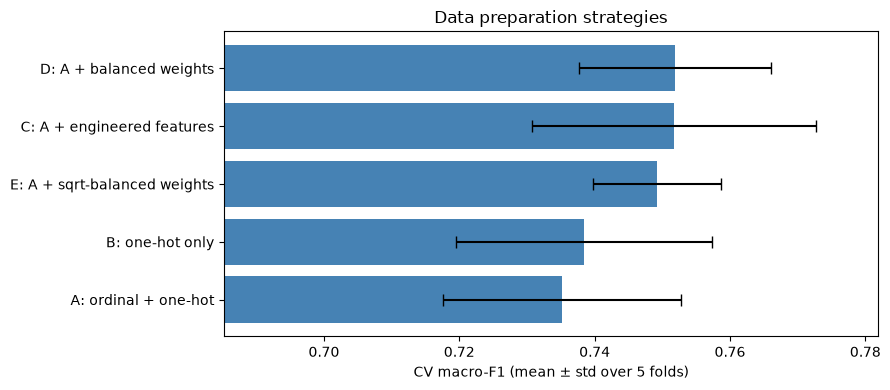

Chosen preparation: C: A + engineered features -> {'use_ordinal': True, 'add_features': True}


In [9]:
from sklearn.utils.class_weight import compute_sample_weight

selection_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
selection_scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": scoring["f1_macro"],
}


def class_weights(y_part, power):
    """'balanced' sample weights n / (K * n_c), raised to `power` (0.5 = dampened)."""
    return compute_sample_weight("balanced", y_part) ** power


def cv_on_train(pipeline, weight_power=None):
    params = None
    if weight_power is not None:
        params = {"classifier__sample_weight": class_weights(y_train, weight_power)}
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=selection_cv,
        scoring=selection_scoring,
        params=params,
        return_train_score=True,
        n_jobs=1,
        error_score="raise",
    )
    return {
        "Train F1 (macro)": scores["train_f1_macro"].mean(),
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
        "CV F1 (macro)": scores["test_f1_macro"].mean(),
        "CV F1 (macro) Std": scores["test_f1_macro"].std(ddof=1),
    }


preparation_strategies = {
    "A: ordinal + one-hot": ({"use_ordinal": True, "add_features": False}, None),
    "B: one-hot only": ({"use_ordinal": False, "add_features": False}, None),
    "C: A + engineered features": ({"use_ordinal": True, "add_features": True}, None),
    "D: A + balanced weights": ({"use_ordinal": True, "add_features": False}, 1.0),
    "E: A + sqrt-balanced weights": ({"use_ordinal": True, "add_features": False}, 0.5),
}
preparation_results = pd.DataFrame(
    {
        name: cv_on_train(build_model(**prep), weight_power)
        for name, (prep, weight_power) in preparation_strategies.items()
    }
).T
preparation_results["Train-CV gap (F1)"] = (
    preparation_results["Train F1 (macro)"] - preparation_results["CV F1 (macro)"]
)
display(preparation_results.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ordered = preparation_results.sort_values("CV F1 (macro)")
ax.barh(
    ordered.index,
    ordered["CV F1 (macro)"],
    xerr=ordered["CV F1 (macro) Std"],
    color="steelblue",
    capsize=4,
)
ax.set(xlabel="CV macro-F1 (mean ± std over 5 folds)", title="Data preparation strategies",
       xlim=(ordered["CV F1 (macro)"].min() - 0.05, ordered["CV F1 (macro)"].max() + 0.03))
fig.tight_layout()
plt.show()

# Preparation (encoding/features) is fixed here; the class weighting is tuned by Optuna below.
structure_names = [name for name, (_, power) in preparation_strategies.items() if power is None]
best_prep_name = preparation_results.loc[structure_names, "CV F1 (macro)"].idxmax()
best_prep = preparation_strategies[best_prep_name][0]
print(f"Chosen preparation: {best_prep_name} -> {best_prep}")

### Interpretation: data preparation

- **Ordinal vs. one-hot (A vs. B):** 0.735 vs. 0.738 macro-F1, i.e. no measurable difference. Trees can reconstruct the order of a quality scale from one-hot columns with a few extra splits. Ordinal encoding is still preferable: fewer features, and a quality scale appears as *one* feature in the importance plots.
- **Engineered features (C):** +0.017 macro-F1 (0.752) with a slightly smaller train-CV gap. `Total SF` combines three areas that a tree would otherwise need several splits to add up; in the final model it is the most frequently used feature. This preparation is used from here on.
- **Class weights (D, E):** `balanced` weights raise the balanced accuracy (= macro recall) from 0.710 to 0.740 and macro-F1 from 0.735 to 0.752, with the smallest spread across folds. This is the expected effect: errors on the rare classes (< 100,000 and ≥ 400,000) cost more, so the model predicts them more often. Because the best strength of the weighting interacts with the other hyperparameters, it is tuned by Optuna (`none` / `sqrt` / `balanced`).
- The differences are about one standard deviation of the CV estimate, so they are indicative rather than significant, but both changes point in the same direction.

## Manual hyperparameter experiments

Starting from the baseline configuration (`n_estimators=350`, `learning_rate=0.05`, `max_depth=5`, `subsample=0.85`, `colsample_bytree=0.85`, `reg_lambda=1`), **one hyperparameter at a time** is changed while all others stay fixed. For each value, training macro-F1 and stratified 5-fold CV macro-F1 are shown:

- **Train high, CV much lower** → the model memorizes the training data (high variance / overfitting).
- **Train and CV both low** → the model is too simple (high bias / underfitting).

What each parameter controls:

| Parameter | Effect |
|---|---|
| `max_depth` | depth of each tree; deeper trees model more feature interactions but overfit faster |
| `learning_rate` ($\eta$) | shrinkage of each tree's contribution; smaller needs more trees but generalizes better |
| `n_estimators` | number of boosting rounds |
| `min_child_weight` | minimum sum of hessians in a leaf; larger → fewer, more robust splits |
| `subsample` | fraction of rows per tree (stochastic boosting, reduces variance) |
| `reg_lambda` | L2 penalty on leaf weights, $\Omega = \gamma T + \frac{1}{2}\lambda \sum_j w_j^2$ |

,Parameter,Value,Train F1 (macro),CV Accuracy,CV Balanced Accuracy,CV F1 (macro),CV F1 (macro) Std,Train-CV gap (F1)
0,max_depth,2.00,0.911,0.756,0.727,0.745,0.028,0.165
1,max_depth,3.00,0.976,0.758,0.718,0.740,0.034,0.236
2,max_depth,5.00,1.000,0.763,0.729,0.752,0.021,0.248
3,max_depth,8.00,1.000,0.761,0.728,0.748,0.023,0.252
4,learning_rate,0.01,0.940,0.738,0.688,0.718,0.018,0.222
5,learning_rate,0.05,1.000,0.763,0.729,0.752,0.021,0.248
6,learning_rate,0.10,1.000,0.763,0.732,0.750,0.027,0.250
7,learning_rate,0.30,1.000,0.748,0.718,0.734,0.021,0.266
8,n_estimators,50.00,0.915,0.728,0.672,0.706,0.020,0.209
9,n_estimators,150.00,0.985,0.759,0.720,0.744,0.025,0.241


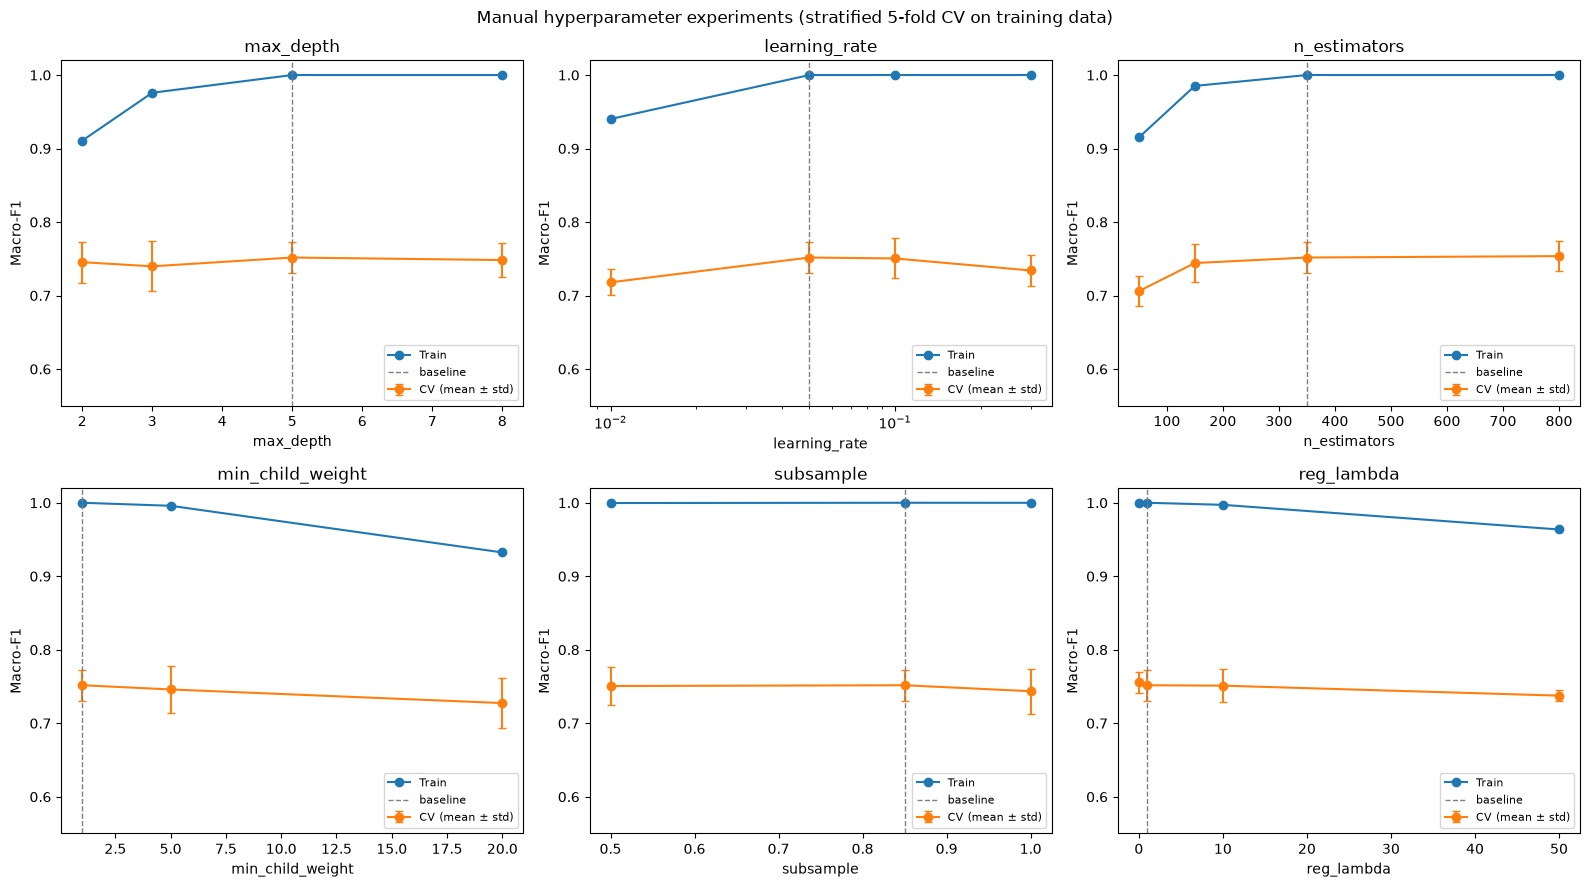

In [10]:
manual_grid = {
    "max_depth": [2, 3, 5, 8],
    "learning_rate": [0.01, 0.05, 0.1, 0.3],
    "n_estimators": [50, 150, 350, 800],
    "min_child_weight": [1, 5, 20],
    "subsample": [0.5, 0.85, 1.0],
    "reg_lambda": [0.0, 1.0, 10.0, 50.0],
}
manual_rows = []
for parameter, values in manual_grid.items():
    for value in values:
        result = cv_on_train(build_model(**best_prep, **{parameter: value}))
        manual_rows.append({"Parameter": parameter, "Value": value, **result})

manual_results = pd.DataFrame(manual_rows)
manual_results["Train-CV gap (F1)"] = (
    manual_results["Train F1 (macro)"] - manual_results["CV F1 (macro)"]
)
display(manual_results.round(3))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (parameter, group) in zip(axes.flat, manual_results.groupby("Parameter", sort=False)):
    ax.plot(group["Value"], group["Train F1 (macro)"], "o-", label="Train")
    ax.errorbar(
        group["Value"],
        group["CV F1 (macro)"],
        yerr=group["CV F1 (macro) Std"],
        fmt="o-",
        capsize=3,
        label="CV (mean ± std)",
    )
    ax.axvline(default_xgb_params.get(parameter, 1), color="gray", linestyle="--",
               linewidth=1, label="baseline")
    if parameter == "learning_rate":
        ax.set_xscale("log")
    ax.set(title=parameter, xlabel=parameter, ylabel="Macro-F1", ylim=(0.55, 1.02))
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Manual hyperparameter experiments (stratified 5-fold CV on training data)")
fig.tight_layout()
plt.show()

### Interpretation: manual hyperparameters

- For almost every setting the **training macro-F1 is ≈ 1.0**, while the CV macro-F1 stays in a narrow band of ≈ 0.74–0.75. The model is in the high-variance regime, and over wide ranges the hyperparameters barely matter; they only matter at the extremes.
- **`max_depth`:** depth 2 gives the smallest gap (train 0.91, gap 0.165) and almost the same CV score (0.745 vs. 0.752 at depth 5). Shallow trees generalize nearly as well; depth 8 brings nothing.
- **`learning_rate` × `n_estimators`:** with 350 trees, $\eta = 0.01$ **underfits** (train 0.94, CV 0.718): too few effective boosting steps. $\eta = 0.3$ takes steps that are too large (CV 0.734, largest gap). Likewise 50 trees underfit (CV 0.706), and from ≈ 350 trees on the CV score plateaus (800: 0.754). With shrinkage, boosting overfits only slowly, so more trees with a small learning rate are safe.
- **`min_child_weight`:** 20 lowers the training F1 (0.93) **and** the CV F1 (0.727). Too much regularization increases the bias, and it hurts the rare classes first: with ≈ 50 training houses in the top class, leaves for that class can no longer be formed.
- **`subsample`:** small effect; 1.0 (no row subsampling) is slightly worse and less stable than 0.5–0.85, so stochastic boosting reduces variance a little.
- **`reg_lambda`:** 0–10 has no visible effect; 50 lowers both training (0.964) and CV F1 (0.737).
- **Conclusion:** no single parameter closes the train-CV gap without also losing CV performance. The parameters interact (e.g. learning rate and number of trees), so they are optimized **jointly** with Optuna, using these experiments to set the search ranges.

## Bayesian optimization with Optuna (TPE)

`TPESampler` (Tree-structured Parzen Estimator) is a sequential model-based (Bayesian) optimizer: after some random start trials it splits the finished trials into "good" (best quantile $\gamma$) and "bad", fits a density $l(x)$ to the good and $g(x)$ to the bad hyperparameters, and proposes the next point by maximizing $l(x)/g(x)$, which is proportional to the expected improvement.

- **Objective:** mean macro-F1 over stratified 5-fold CV on the training set.
- **Search space:** the hyperparameters from the manual experiments plus `colsample_bytree`, `gamma`, `reg_alpha`, and the class weighting (`none`, `sqrt`, `balanced`).
- **Pruning:** after each fold, the running mean is reported; `MedianPruner` stops trials that are clearly worse than the median of earlier trials at the same fold.
- **Saving intermediate steps:** the study is stored in `optuna_lab2.db` (SQLite), and every finished trial is also written to `optuna_lab2_trials.csv`. Re-running the cell **continues** the stored study up to `N_TRIALS` instead of starting over. Delete `optuna_lab2.db` to start from scratch (needed if the search space or the preparation changes).

In [11]:
import warnings

import optuna
from optuna.visualization import matplotlib as optuna_plots

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

N_TRIALS = 40
weight_powers = {"none": None, "sqrt": 0.5, "balanced": 1.0}


def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 800, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 12),
        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.1, 1.0),
        "gamma": trial.suggest_float("gamma", 1e-3, 5.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 50.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
    }
    weight_power = weight_powers[
        trial.suggest_categorical("class_weighting", list(weight_powers))
    ]
    pipeline = build_model(**best_prep, **params)

    fold_scores = []
    for fold, (train_index, val_index) in enumerate(selection_cv.split(X_train, y_train)):
        X_fold_train, X_fold_val = X_train.iloc[train_index], X_train.iloc[val_index]
        y_fold_train, y_fold_val = y_train.iloc[train_index], y_train.iloc[val_index]
        fit_params = {}
        if weight_power is not None:
            fit_params["classifier__sample_weight"] = class_weights(y_fold_train, weight_power)
        fitted = clone(pipeline).fit(X_fold_train, y_fold_train, **fit_params)
        fold_scores.append(
            f1_score(y_fold_val, fitted.predict(X_fold_val), average="macro", zero_division=0)
        )
        trial.report(float(np.mean(fold_scores)), fold)
        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("cv_f1_std", float(np.std(fold_scores, ddof=1)))
    return float(np.mean(fold_scores))


def save_progress(study, trial):
    study.trials_dataframe().to_csv("optuna_lab2_trials.csv", index=False)


study = optuna.create_study(
    study_name="lab2_xgboost_macro_f1",
    storage="sqlite:///optuna_lab2.db",
    load_if_exists=True,
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42, n_startup_trials=10),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=1),
)
finished_states = (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED)
remaining_trials = N_TRIALS - sum(trial.state in finished_states for trial in study.trials)
if remaining_trials > 0:
    study.optimize(objective, n_trials=remaining_trials, callbacks=[save_progress])

trial_states = pd.Series([trial.state.name for trial in study.trials]).value_counts()
print(trial_states.to_string())
print(f"\nBest CV macro-F1: {study.best_value:.3f} (trial {study.best_trial.number}, "
      f"std over folds {study.best_trial.user_attrs['cv_f1_std']:.3f})")
display(pd.Series(study.best_params, name="best value").to_frame())

top_trials = (
    study.trials_dataframe()
    .query("state == 'COMPLETE'")
    .sort_values("value", ascending=False)
    .head(10)
)
display(top_trials.filter(regex="^(number|value|params_|user_attrs_)").round(4))

COMPLETE    30
PRUNED      10

Best CV macro-F1: 0.779 (trial 37, std over folds 0.025)


,best value
n_estimators,750
learning_rate,0.028037
max_depth,7
min_child_weight,1.131869
subsample,0.675387
colsample_bytree,0.439773
gamma,0.016764
reg_lambda,0.001664
reg_alpha,0.002735
class_weighting,balanced


,number,value,params_class_weighting,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_alpha,params_reg_lambda,params_subsample,user_attrs_cv_f1_std
37,37,0.7787,balanced,0.4398,0.0168,0.0280,7,1.1319,750,0.0027,0.0017,0.6754,0.0251
35,35,0.7777,balanced,0.4011,0.0189,0.0350,6,1.2441,650,0.0057,0.0020,0.6538,0.0163
27,27,0.7720,balanced,0.2982,0.6645,0.0317,6,1.1492,800,0.0054,0.0048,0.7227,0.0215
39,39,0.7715,balanced,0.4143,0.0422,0.0211,7,1.1893,700,0.0010,0.0018,0.7744,0.0151
10,10,0.7698,balanced,0.3103,0.0560,0.0520,4,1.6431,750,0.0136,0.0060,0.7362,0.0260
31,31,0.7676,balanced,0.2889,0.0318,0.0529,6,1.1394,750,0.0057,0.0107,0.6894,0.0225
14,14,0.7658,balanced,0.1598,0.3793,0.0229,3,1.2961,800,0.0067,0.0059,0.6890,0.0157
21,21,0.7654,balanced,0.1802,0.4603,0.0232,7,2.4488,750,0.0019,0.2958,0.8471,0.0220
38,38,0.7653,balanced,0.3800,0.7066,0.0229,4,1.2648,800,0.0361,0.0043,0.7259,0.0184
22,22,0.7645,balanced,0.3388,0.4551,0.0258,3,1.6975,700,0.0093,0.0288,0.8124,0.0181


### Visualizing the optimization process

- **Optimization history:** CV macro-F1 per trial and the best value so far. The first 10 trials are random (startup); afterwards TPE should concentrate on better regions.
- **Intermediate values:** running mean per fold; lines that stop early are pruned trials.
- **Hyperparameter importances:** how much of the variation in the objective each hyperparameter explains (fANOVA).
- **Slice / contour plots:** objective vs. single hyperparameters and pairs; dark points are later trials.

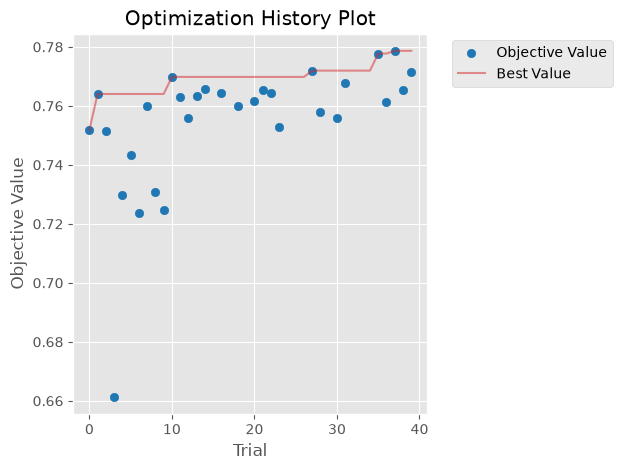

/Users/andreipop/Desktop/ML/LabML/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.canvas.print_figure(bytes_io, **kw)


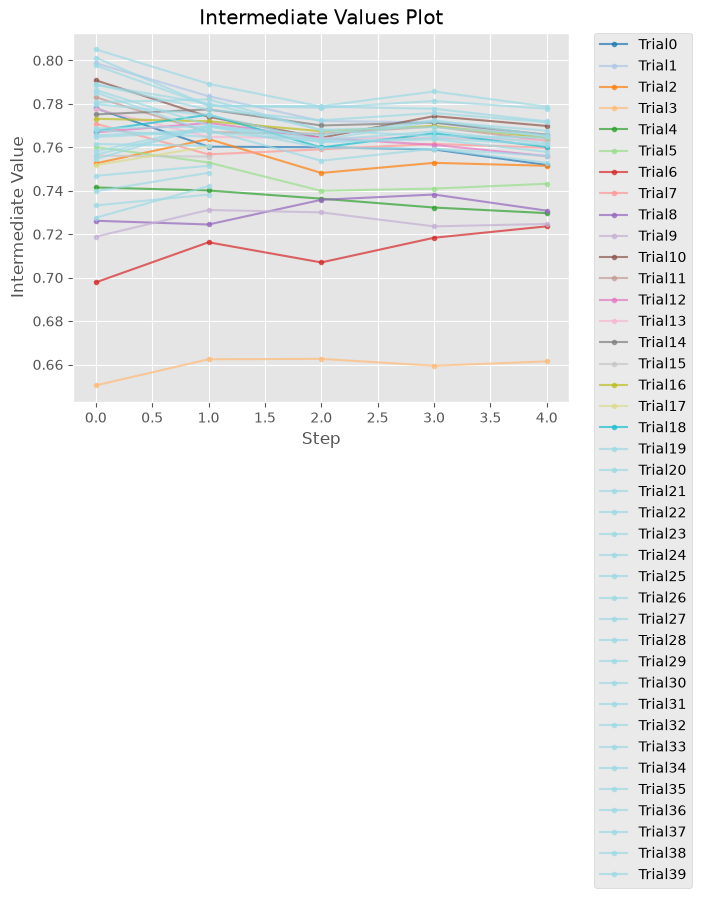

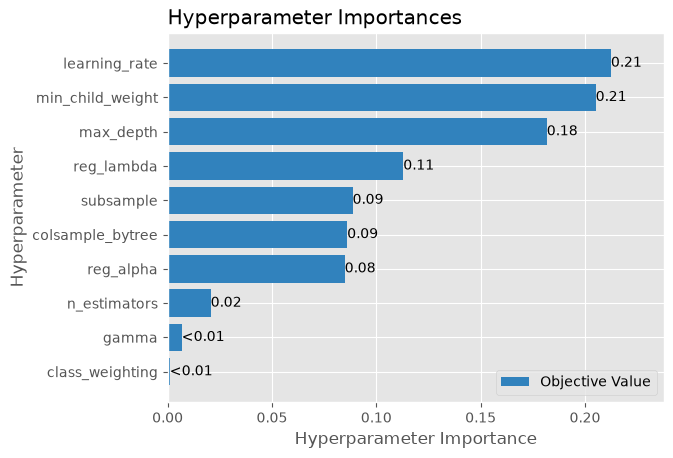

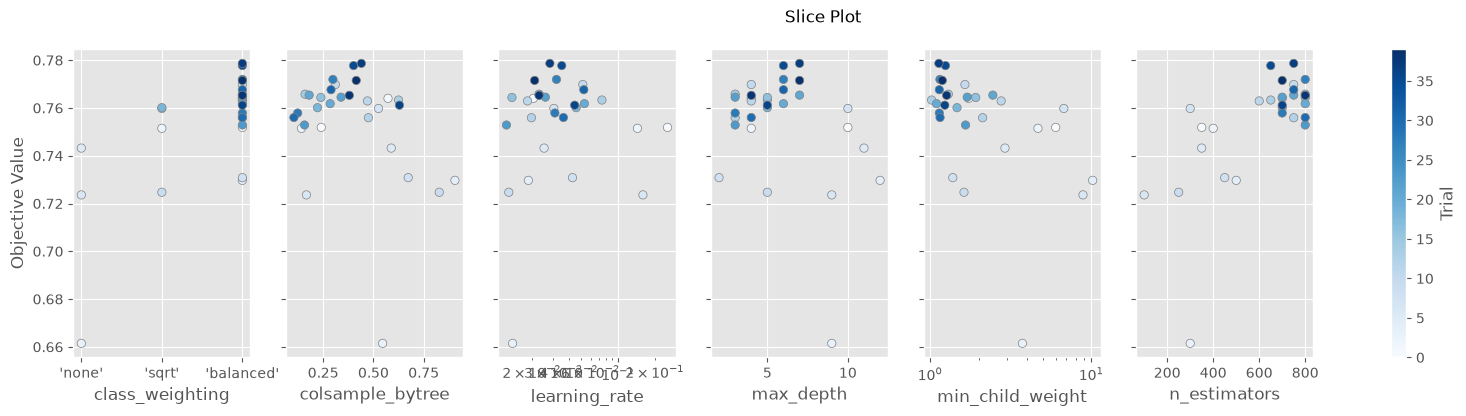

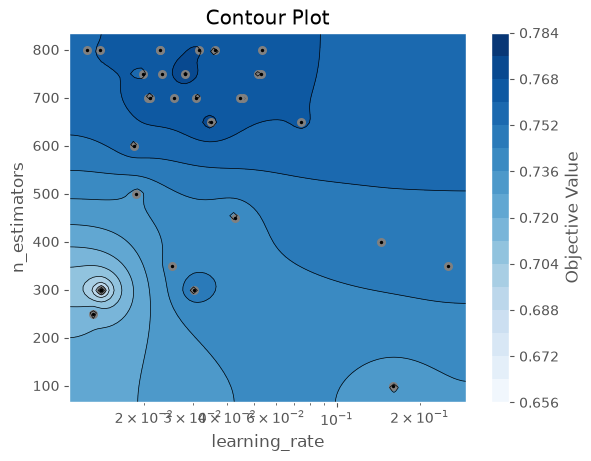

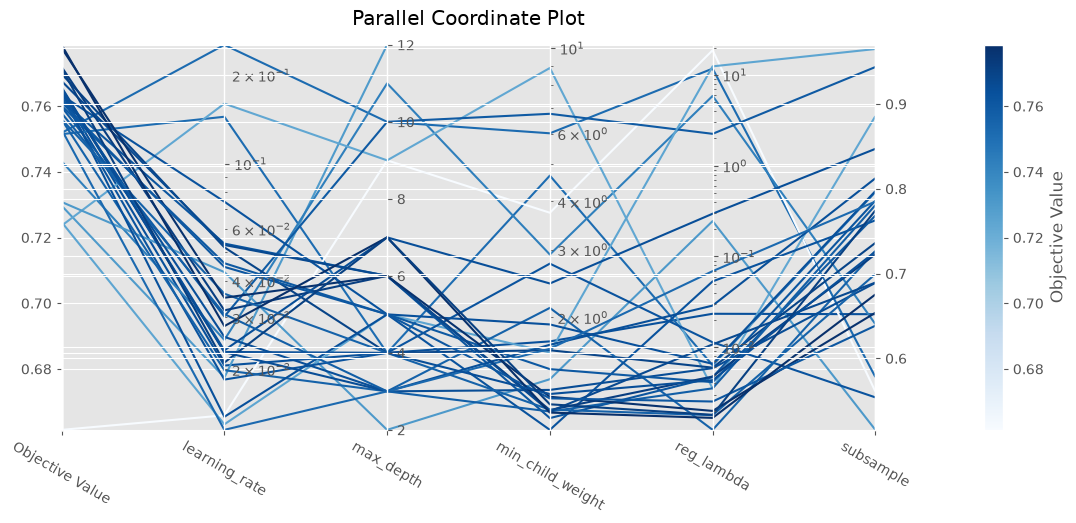

In [12]:
optuna_plots.plot_optimization_history(study)
plt.show()

optuna_plots.plot_intermediate_values(study)
plt.show()

optuna_plots.plot_param_importances(study)
plt.show()

optuna_plots.plot_slice(
    study,
    params=["learning_rate", "max_depth", "n_estimators", "min_child_weight",
            "colsample_bytree", "class_weighting"],
)
plt.gcf().set_size_inches(20, 4)
plt.show()

optuna_plots.plot_contour(study, params=["learning_rate", "n_estimators"])
plt.show()

optuna_plots.plot_parallel_coordinate(
    study, params=["learning_rate", "max_depth", "min_child_weight", "subsample", "reg_lambda"]
)
plt.gcf().set_size_inches(14, 5)
plt.show()

### Interpretation: Optuna

- 40 trials: 30 completed, 10 stopped early by the pruner, which saved about a quarter of the computation. In the optimization history the first 10 (random) trials scatter widely; after that TPE proposes mostly good configurations.
- **Best CV macro-F1: 0.779** (baseline 0.735, chosen preparation with default hyperparameters 0.752).
- **Class weighting:** TPE quickly concentrated on `balanced` (33 of 40 trials), and all of the top 10 trials use it, consistent with the data-preparation experiment.
- **Best configuration:** many trees (750) with a small learning rate (0.028), depth 7, and strong **row and column subsampling** (`subsample` ≈ 0.68, `colsample_bytree` ≈ 0.44), while `reg_lambda`/`reg_alpha` are close to 0. Randomization, not the L1/L2 penalties, is the effective regularizer here. Column subsampling (0.16–0.44 in the top trials) decorrelates the trees, similar to a random forest, which helps with ≈ 250 mostly sparse one-hot features.
- **Search space:** in a first run, the best trials sat at the upper limit `max_depth = 8`. The range was widened to 2–12 and the study repeated; the optimum (7) is now inside the range.
- **Caveat:** the best CV value is optimistic, because it is the maximum of 40 noisy estimates (fold std of the best trial: 0.025).

## Final model

The final model uses the chosen preparation and the best Optuna hyperparameters (including the class weighting), refit on the **whole 80% training set**. It is compared once with the hand-tuned baseline on the held-out test set. All plots in the diagnostics section below are for this final model.

In [13]:
final_params = dict(study.best_params)
final_weight_power = weight_powers[final_params.pop("class_weighting")]
final_fit_params = {}
if final_weight_power is not None:
    final_fit_params["classifier__sample_weight"] = class_weights(y_train, final_weight_power)

final_model = build_model(**best_prep, **final_params)
final_model.fit(X_train, y_train, **final_fit_params)


def test_metrics(fitted_model):
    predictions = fitted_model.predict(X_test)
    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Precision (macro)": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, predictions, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_test, predictions, average="weighted", zero_division=0),
    }


comparison = pd.DataFrame(
    {
        "Baseline (hand-tuned)": {
            "CV F1 (macro), train set": preparation_results.loc["A: ordinal + one-hot", "CV F1 (macro)"],
            **test_metrics(model),
        },
        "Final (Optuna)": {
            "CV F1 (macro), train set": study.best_value,
            **test_metrics(final_model),
        },
    }
)
comparison["Difference"] = comparison["Final (Optuna)"] - comparison["Baseline (hand-tuned)"]
display(comparison.round(3))

,Baseline (hand-tuned),Final (Optuna),Difference
"CV F1 (macro), train set",0.735,0.779,0.043
Accuracy,0.771,0.770,-0.002
Balanced Accuracy,0.723,0.738,0.015
Precision (macro),0.770,0.746,-0.024
Recall (macro),0.723,0.738,0.015
F1 (macro),0.742,0.741,-0.001
F1 (weighted),0.770,0.770,-0.000


### Interpretation: baseline vs. final model on the test set

- In cross-validation the tuned model is clearly better (+0.043 macro-F1). On the test set, both models reach the same macro-F1 (0.741 vs. 0.742). The tuned model has **higher macro recall / balanced accuracy (+0.015)** and **lower macro precision (−0.024)**. This is the typical effect of class weighting: rare classes are predicted more often, so more of them are found, with more false positives.
- Why the CV gain does not appear on the test set:
  1. The best CV value is biased upward (selection among 40 trials).
  2. The test set is small for macro-F1: with 13 houses in the top class, **one** house changes that class's F1 by ≈ 0.04 and macro-F1 by ≈ 0.007. Differences of 0.01–0.02 cannot be detected reliably, whereas the CV comparison uses all 2,344 training houses.
  3. The baseline hyperparameters were already in the flat region found in the manual experiments.
- The tuned model is kept as the final model, because it was selected by the more reliable procedure and it is better on the rare classes. Its true advantage is probably smaller than the 0.043 measured in CV.

## Model diagnostics


### Shared setup
Run once before the sections below. The cells use the final tuned model (`final_model`) and the held-out test set, which was not used for any choice before this point.

In [14]:
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
import json
import textwrap

class_ids = np.arange(len(class_names))
y_test_array = np.asarray(y_test)
y_pred = final_model.predict(X_test)
y_pred_probability = final_model.predict_proba(X_test)
print("Diagnostics setup complete. Run the following cells in order.")

Diagnostics setup complete. Run the following cells in order.


### Classification metrics
Accuracy is overall correctness. Macro averages weight each class equally; weighted averages account for class frequency.


In [15]:
metrics_table = pd.DataFrame(
    {
        "Metric": [
            "Precision (macro)", "Recall (macro)", "F1 (macro)",
            "Precision (weighted)", "Recall (weighted)", "F1 (weighted)",
        ],
        "Score": [
            precision_score(y_test_array, y_pred, labels=class_ids, average="macro", zero_division=0),
            recall_score(y_test_array, y_pred, labels=class_ids, average="macro", zero_division=0),
            f1_score(y_test_array, y_pred, labels=class_ids, average="macro", zero_division=0),
            precision_score(y_test_array, y_pred, labels=class_ids, average="weighted", zero_division=0),
            recall_score(y_test_array, y_pred, labels=class_ids, average="weighted", zero_division=0),
            f1_score(y_test_array, y_pred, labels=class_ids, average="weighted", zero_division=0),
        ],
    }
)
print(f"Test accuracy: {accuracy_score(y_test_array, y_pred):.3f}")
display(metrics_table.round(3))

per_class_report = classification_report(
    y_test_array,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
display(
    pd.DataFrame(per_class_report)
    .T.loc[class_names, ["precision", "recall", "f1-score", "support"]]
    .round(3)
)


Test accuracy: 0.770


,Metric,Score
0,Precision (macro),0.746
1,Recall (macro),0.738
2,F1 (macro),0.741
3,Precision (weighted),0.771
4,Recall (weighted),0.770
5,F1 (weighted),0.770


,precision,recall,f1-score,support
< 100.000,0.717,0.688,0.702,48.0
100.000 - < 130.000,0.655,0.706,0.679,102.0
130.000 - < 180.000,0.795,0.807,0.801,207.0
180.000 - < 250.000,0.824,0.752,0.786,137.0
250.000 - < 400.000,0.819,0.861,0.840,79.0
>= 400.000,0.667,0.615,0.640,13.0


**Interpretation.** Weighted F1 (0.770) is higher than macro F1 (0.741), because the frequent middle classes are predicted better than the rare ones. The best class is 250,000–400,000 (F1 0.84). The weakest are ≥ 400,000 (F1 0.64, only 13 test houses) and 100,000–130,000 (F1 0.68): the latter is a narrow price band (30,000 wide) between two large neighboring classes.

### Confusion matrix
Rows are the actual classes; columns are the predicted classes.


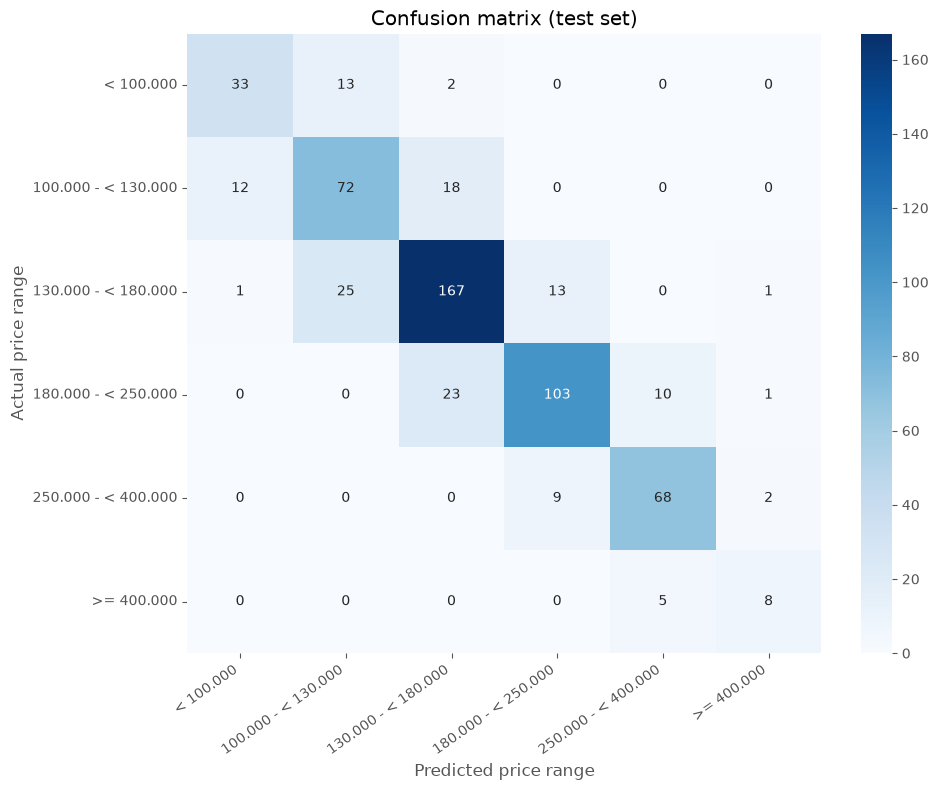

In [16]:
cm = confusion_matrix(y_test_array, y_pred, labels=class_ids)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names,
)
plt.xlabel("Predicted price range")
plt.ylabel("Actual price range")
plt.title("Confusion matrix (test set)")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


**Interpretation.** Almost all errors are between **neighboring** price classes: of 135 misclassified test houses, 130 are off by exactly one class. The classes are bins of a continuous price, and a house close to a boundary (e.g. 128,000 vs. 132,000) is hard to place, so 77% accuracy understates how close the predictions are. The largest confusions are 130–180k → 100–130k (25) and 180–250k → 130–180k (23).

### ROC curves
Each panel treats one price range as positive and all other ranges as negative.


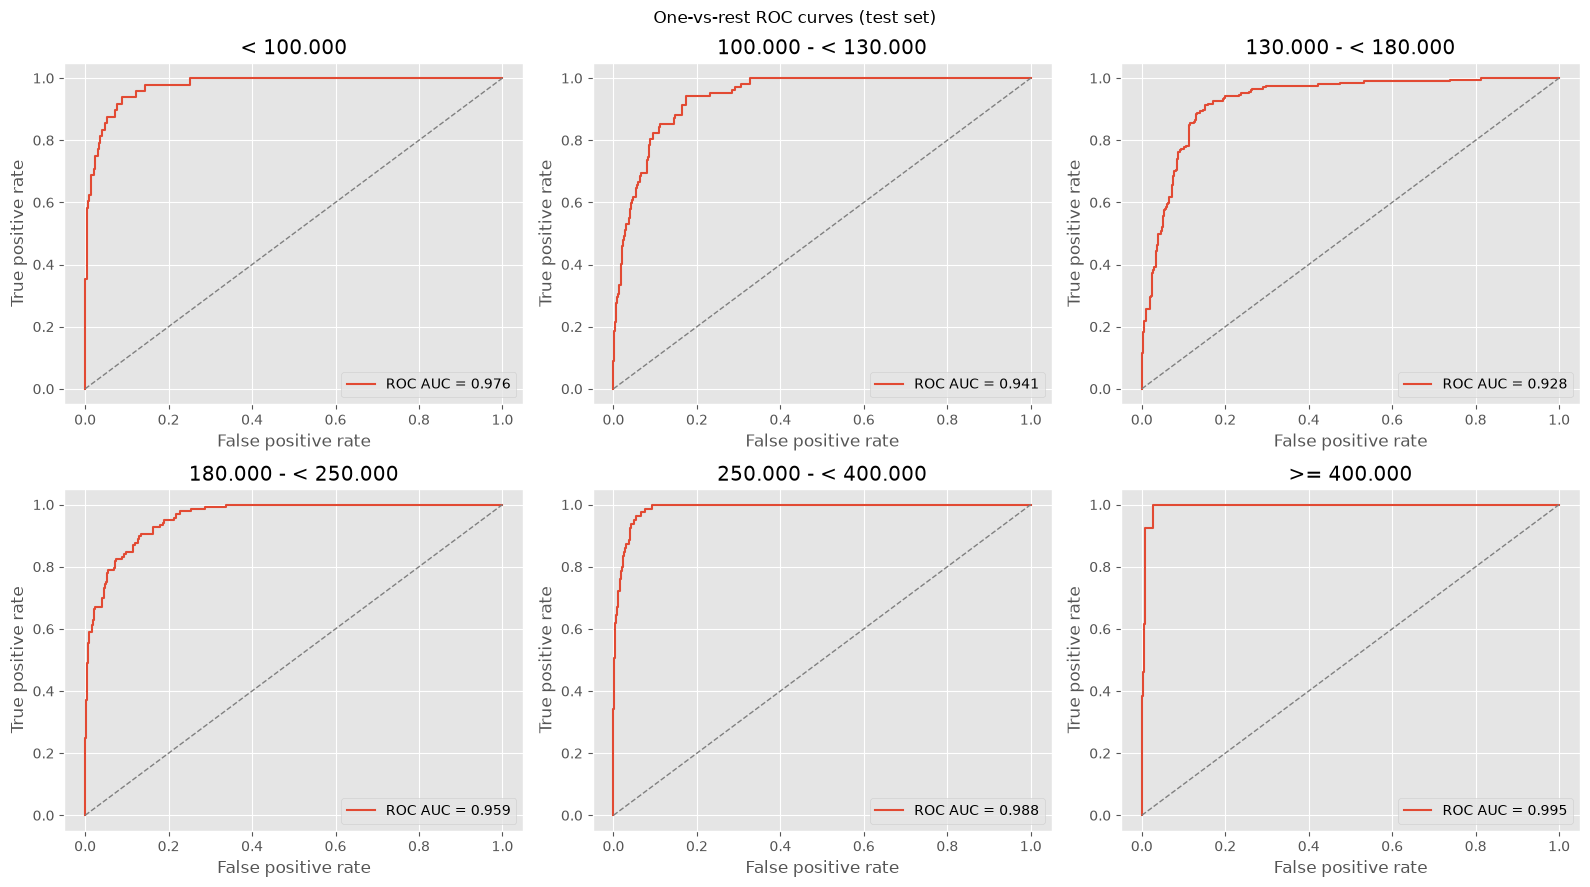

,Price range,ROC AUC
0,< 100.000,0.976
1,100.000 - < 130.000,0.941
2,130.000 - < 180.000,0.928
3,180.000 - < 250.000,0.959
4,250.000 - < 400.000,0.988
5,>= 400.000,0.995


In [17]:
# Multiclass ROC is shown one-vs-rest: one curve per price-range class.
roc_scores = []
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for class_id, ax in enumerate(axes.flat):
    binary_truth = (y_test_array == class_id).astype(int)
    fpr, tpr, _ = roc_curve(binary_truth, y_pred_probability[:, class_id])
    roc_auc = roc_auc_score(binary_truth, y_pred_probability[:, class_id])
    roc_scores.append({"Price range": class_names[class_id], "ROC AUC": roc_auc})
    ax.plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.3f}")
    ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
    ax.set(title=class_names[class_id], xlabel="False positive rate", ylabel="True positive rate")
    ax.legend(loc="lower right")
fig.suptitle("One-vs-rest ROC curves (test set)")
fig.tight_layout()
plt.show()
display(pd.DataFrame(roc_scores).round(3))

**Interpretation.** One-vs-rest AUC is between 0.93 and 0.995. The **outer** classes (< 100,000: 0.976, ≥ 400,000: 0.995) are easiest to separate from the rest because they have only one neighbor. The middle class 130,000–180,000 (0.928) has two neighbors on either side. For the rare top class the ROC curve is optimistic: the false positive rate is divided by 573 negatives, so even several false positives barely move the curve. The precision-recall curve below is more informative for that class.

### Precision-recall curves
Each panel is one-vs-rest. The dashed line shows the share of test examples in that class.


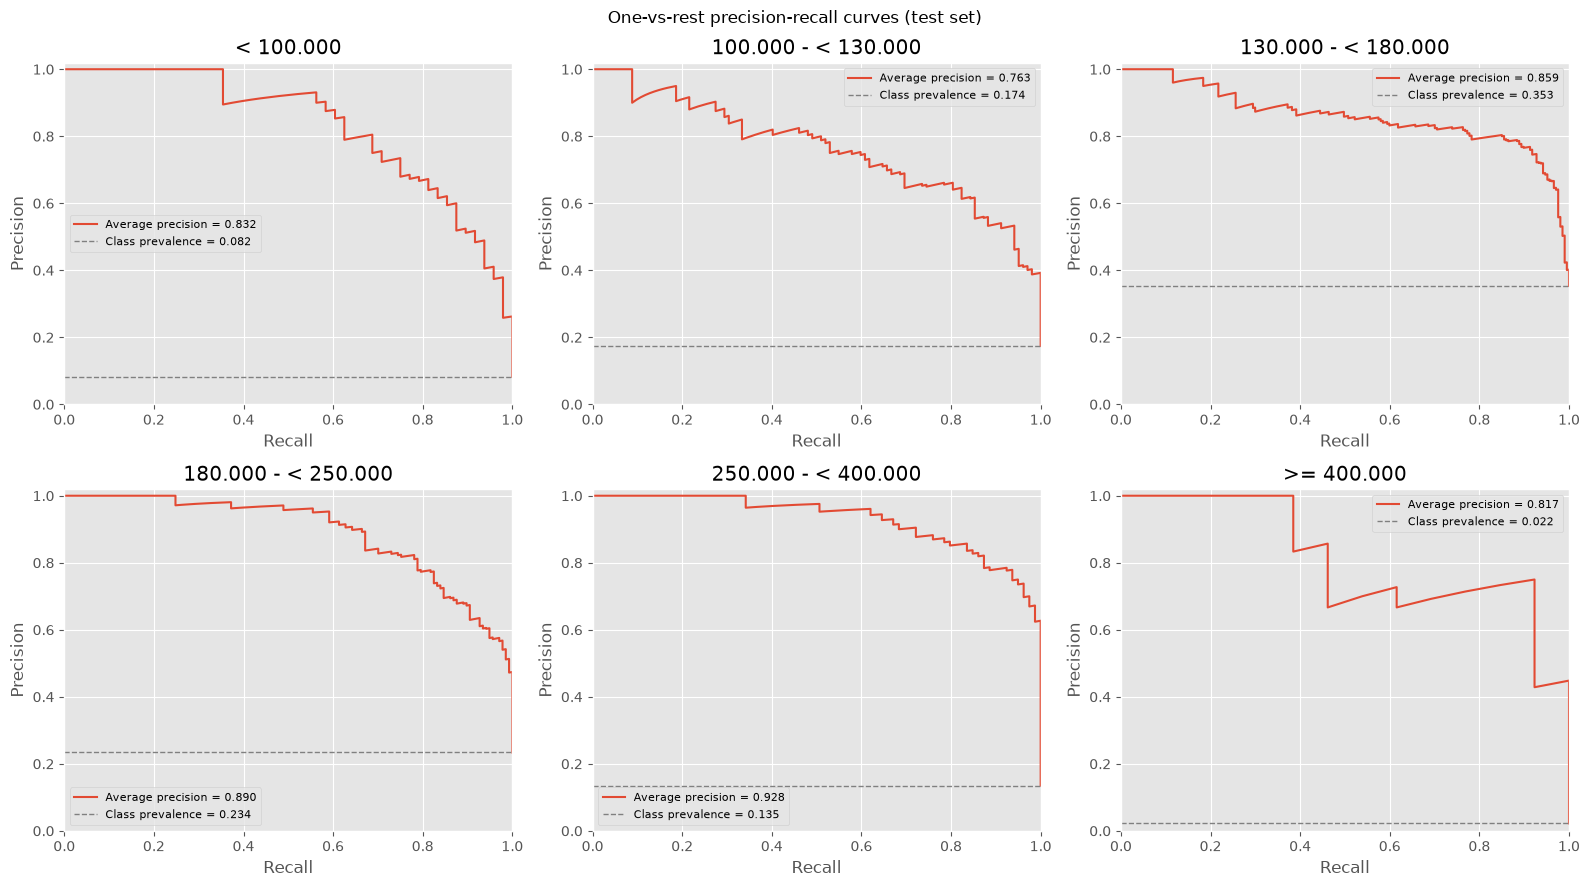

,Price range,Average precision
0,< 100.000,0.832
1,100.000 - < 130.000,0.763
2,130.000 - < 180.000,0.859
3,180.000 - < 250.000,0.890
4,250.000 - < 400.000,0.928
5,>= 400.000,0.817


In [18]:
# Precision-recall is shown one-vs-rest; the dashed line is each class's prevalence.
pr_scores = []
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for class_id, ax in enumerate(axes.flat):
    binary_truth = (y_test_array == class_id).astype(int)
    precision_curve, recall_curve, _ = precision_recall_curve(
        binary_truth, y_pred_probability[:, class_id]
    )
    average_precision = average_precision_score(binary_truth, y_pred_probability[:, class_id])
    pr_scores.append({"Price range": class_names[class_id], "Average precision": average_precision})
    ax.plot(recall_curve, precision_curve, label=f"Average precision = {average_precision:.3f}")
    ax.axhline(
        binary_truth.mean(), linestyle="--", color="gray", linewidth=1,
        label=f"Class prevalence = {binary_truth.mean():.3f}",
    )
    ax.set(
        title=class_names[class_id], xlabel="Recall", ylabel="Precision",
        xlim=(0, 1), ylim=(0, 1.02),
    )
    ax.legend(loc="best", fontsize=8)
fig.suptitle("One-vs-rest precision-recall curves (test set)")
fig.tight_layout()
plt.show()
display(pd.DataFrame(pr_scores).round(3))

**Interpretation.** Average precision ranges from 0.76 (100,000–130,000) to 0.93 (250,000–400,000). For the top class it is 0.82 with a prevalence of only 0.022, about 37× better than random. The drop in precision at high recall shows the cost of finding the last houses of a class: they lie at the class boundaries and overlap with the neighbors.

### Tune probability thresholds for macro-F1
This performs cross-validation on training data to choose one cutoff per class, then evaluates once on the held-out test set.


In [19]:
# Select class-specific cutoffs using only out-of-fold training probabilities.
threshold_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probability = cross_val_predict(
    clone(final_model),
    X_train,
    y_train,
    cv=threshold_cv,
    method="predict_proba",
    n_jobs=1,
    params=final_fit_params or None,
)
y_train_array = np.asarray(y_train)


def predict_with_thresholds(probabilities, thresholds):
    eligible = probabilities >= thresholds
    eligible_probabilities = np.where(eligible, probabilities, -np.inf)
    predictions = eligible_probabilities.argmax(axis=1)
    no_match = ~eligible.any(axis=1)
    predictions[no_match] = probabilities[no_match].argmax(axis=1)
    return predictions


def macro_f1_at_thresholds(thresholds):
    return f1_score(
        y_train_array,
        predict_with_thresholds(oof_probability, thresholds),
        labels=class_ids,
        average="macro",
        zero_division=0,
    )


threshold_candidates = [
    np.unique(
        np.r_[
            0.0,
            np.quantile(oof_probability[:, class_id], np.linspace(0, 1, 101)),
            1.0,
        ]
    )
    for class_id in class_ids
]
best_thresholds = None
best_oof_macro_f1 = -1.0
for start in (0.25, 0.5, 0.75):
    thresholds = np.full(len(class_ids), start, dtype=float)
    for _ in range(5):
        changed = False
        for class_id, candidates in enumerate(threshold_candidates):
            scores = []
            for cutoff in candidates:
                trial = thresholds.copy()
                trial[class_id] = cutoff
                scores.append(macro_f1_at_thresholds(trial))
            chosen = candidates[int(np.argmax(scores))]
            if chosen != thresholds[class_id]:
                thresholds[class_id] = chosen
                changed = True
        if not changed:
            break
    score = macro_f1_at_thresholds(thresholds)
    if score > best_oof_macro_f1:
        best_oof_macro_f1 = score
        best_thresholds = thresholds.copy()

default_oof_f1 = f1_score(
    y_train_array,
    oof_probability.argmax(axis=1),
    labels=class_ids,
    average="macro",
    zero_division=0,
)
tuned_test_predictions = predict_with_thresholds(y_pred_probability, best_thresholds)
tuned_test_f1 = f1_score(
    y_test_array,
    tuned_test_predictions,
    labels=class_ids,
    average="macro",
    zero_division=0,
)
print(f"OOF macro-F1 before tuning (argmax): {default_oof_f1:.3f}")
print(f"Best OOF macro-F1 found by threshold search: {best_oof_macro_f1:.3f}")
print(f"Test macro-F1 with default argmax: "
      f"{f1_score(y_test_array, y_pred, labels=class_ids, average='macro', zero_division=0):.3f}")
print(f"Test macro-F1 with tuned cutoffs: {tuned_test_f1:.3f}")
display(pd.DataFrame({
    "Price range": class_names,
    "Chosen probability cutoff": best_thresholds,
}).round(3))
print(
    "Decision rule: among classes that meet their cutoff, choose the one with "
    "the highest probability; if none meet a cutoff, choose the overall "
    "highest-probability class."
)

OOF macro-F1 before tuning (argmax): 0.776
Best OOF macro-F1 found by threshold search: 0.778
Test macro-F1 with default argmax: 0.741
Test macro-F1 with tuned cutoffs: 0.741


,Price range,Chosen probability cutoff
0,< 100.000,0.488
1,100.000 - < 130.000,0.496
2,130.000 - < 180.000,0.350
3,180.000 - < 250.000,0.452
4,250.000 - < 400.000,0.568
5,>= 400.000,0.475


Decision rule: among classes that meet their cutoff, choose the one with the highest probability; if none meet a cutoff, choose the overall highest-probability class.


**Interpretation.** The threshold search improves the out-of-fold macro-F1 only marginally (0.776 → 0.778), and on the test set the macro-F1 is unchanged (0.741). Because the final model is trained with `balanced` class weights, its probabilities are already shifted toward the rare classes, so plain argmax is already close to the macro-F1-optimal decision. The chosen cutoffs are all moderate (0.35–0.57). With six cutoffs fitted to the training predictions, the small OOF gain is within the range of overfitting, so the final model uses **argmax**.

### Feature importance: gain and split count
Gain measures average loss reduction from splits on a feature. Split count is how often the feature is used.


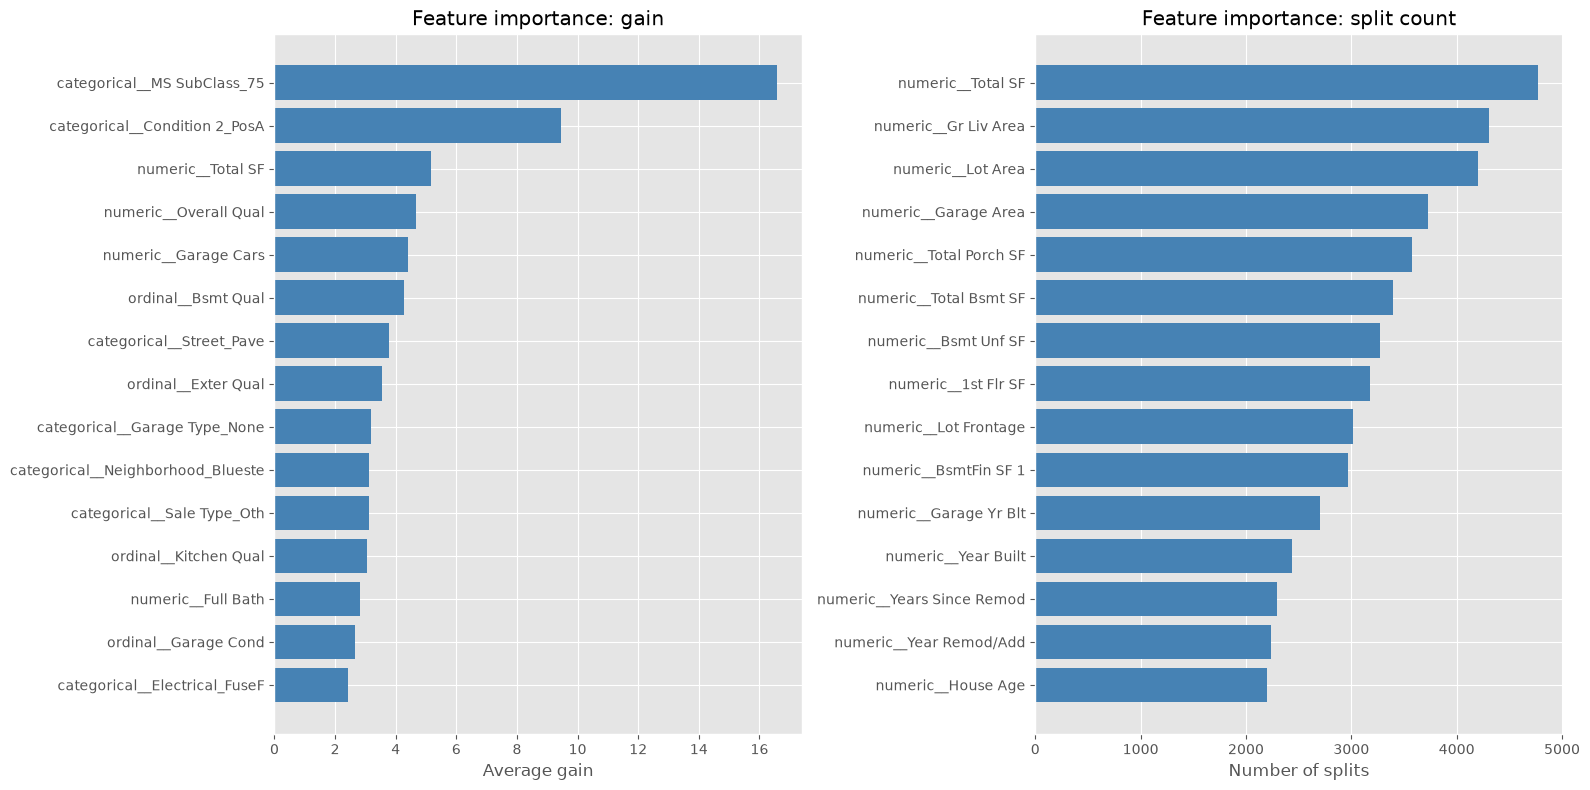

,gain,split
categorical__MS SubClass_75,16.575,1.0
categorical__Condition 2_PosA,9.445,6.0
numeric__Total SF,5.170,4769.0
numeric__Overall Qual,4.653,2023.0
numeric__Garage Cars,4.403,548.0
ordinal__Bsmt Qual,4.258,641.0
categorical__Street_Pave,3.784,1.0
ordinal__Exter Qual,3.560,310.0
categorical__Garage Type_None,3.170,21.0
categorical__Neighborhood_Blueste,3.126,3.0


In [20]:
# Gain is average split improvement; weight is the number of times a feature splits.
xgb_model = final_model.named_steps["classifier"]
booster = xgb_model.get_booster()
feature_names = list(final_model.named_steps["preprocessor"].get_feature_names_out())


def importance_by_name(importance_type):
    raw_scores = booster.get_score(importance_type=importance_type)
    values = np.zeros(len(feature_names), dtype=float)
    for key, value in raw_scores.items():
        if key.startswith("f") and key[1:].isdigit():
            feature_index = int(key[1:])
            if feature_index < len(values):
                values[feature_index] = value
        elif key in feature_names:
            values[feature_names.index(key)] = value
    return pd.Series(values, index=feature_names, name=importance_type)


importance = pd.concat(
    [importance_by_name("gain"), importance_by_name("weight")], axis=1
).rename(columns={"weight": "split"})
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, column, title in zip(
    axes,
    ("gain", "split"),
    ("Feature importance: gain", "Feature importance: split count"),
):
    top = importance[column].nlargest(15).sort_values()
    ax.barh(top.index, top.values, color="steelblue")
    ax.set_title(title)
    ax.set_xlabel("Average gain" if column == "gain" else "Number of splits")
fig.tight_layout()
plt.show()
display(importance.sort_values("gain", ascending=False).head(15).round(3))

**Interpretation.**
- **Gain** is the *average* loss reduction per split, and **split** is the number of splits on a feature. The two rankings differ strongly.
- The top features by gain include rare one-hot columns (`MS SubClass_75`, `Street_Pave`, `Condition 2_PosA`) that are used only **once or a few times**, but in a split with a large gain. Average gain is unreliable for such rarely used features.
- Features that rank high in **both** views are the robust drivers: `Total SF` (engineered; by far the most splits), `Overall Qual`, `Garage Cars`, `Bsmt Qual`, `Exter Qual` and `Kitchen Qual`. Size and quality determine the price class, which agrees with the correlation analysis in Task 1. The ordinal encoding pays off here: each quality scale shows up as a single, interpretable feature.
- Importance is predictive, not causal.

### Decision tree visualizations
The model has no early stopping, so “best tree” here means the individual tree with the highest sum of split gains. Run the helper cell once.


In [21]:
# There is no early stopping in this fit; define "best tree" as the individual
# tree with the largest sum of split gains, not a best boosting iteration.
tree_dumps = [
    json.loads(tree)
    for tree in booster.get_dump(dump_format="json", with_stats=True)
]


def sum_tree_gain(node):
    return float(node.get("gain", 0.0)) + sum(
        sum_tree_gain(child) for child in node.get("children", [])
    )


tree_gains = np.array([sum_tree_gain(tree) for tree in tree_dumps])
best_tree_index = int(tree_gains.argmax())


def draw_tree(tree, title):
    positions = {}
    next_leaf = [0]

    def assign_positions(node, depth=0):
        children = node.get("children", [])
        if children:
            child_x = [assign_positions(child, depth + 1) for child in children]
            x_position = sum(child_x) / len(child_x)
        else:
            x_position = next_leaf[0]
            next_leaf[0] += 1
        positions[node["nodeid"]] = (x_position, -depth)
        return x_position

    assign_positions(tree)
    max_depth = max(-point[1] for point in positions.values())
    fig, ax = plt.subplots(
        figsize=(max(14, next_leaf[0] * 0.55), max(7, max_depth * 1.8))
    )

    def render(node):
        x_position, y_position = positions[node["nodeid"]]
        children = node.get("children", [])
        if "leaf" in node:
            label = f"leaf = {float(node['leaf']):.2f}"
            color = "#e8f1fa"
        else:
            split_name = node["split"]
            if split_name.startswith("f") and split_name[1:].isdigit():
                split_name = feature_names[int(split_name[1:])]
            split_name = textwrap.shorten(split_name, width=30, placeholder="...")
            label = f"{split_name}\\n<= {float(node['split_condition']):.3g}"
            color = "#fff1cc"
        ax.text(
            x_position,
            y_position,
            label,
            ha="center",
            va="center",
            fontsize=7,
            bbox={"boxstyle": "round,pad=0.3", "facecolor": color, "edgecolor": "#555"},
        )
        for child in children:
            child_x, child_y = positions[child["nodeid"]]
            ax.plot(
                [x_position, child_x],
                [y_position - 0.08, child_y + 0.12],
                color="#666",
                linewidth=0.8,
            )
            render(child)

    render(tree)
    ax.set_title(title)
    ax.axis("off")
    ax.set_xlim(-1, max(1, next_leaf[0]))
    ax.set_ylim(-max_depth - 0.7, 0.7)
    fig.tight_layout()
    plt.show()


def show_tree(tree_index):
    boosting_round = tree_index // len(class_ids)
    tree_class = tree_index % len(class_ids)
    print(
        f"Tree {tree_index}; round {boosting_round}; class {class_names[tree_class]}; "
        f"sum of split gains {tree_gains[tree_index]:.2f}"
    )
    draw_tree(
        tree_dumps[tree_index],
        f"XGBoost tree {tree_index} - {class_names[tree_class]}",
    )



#### First tree


Tree 0; round 0; class < 100.000; sum of split gains 609.61


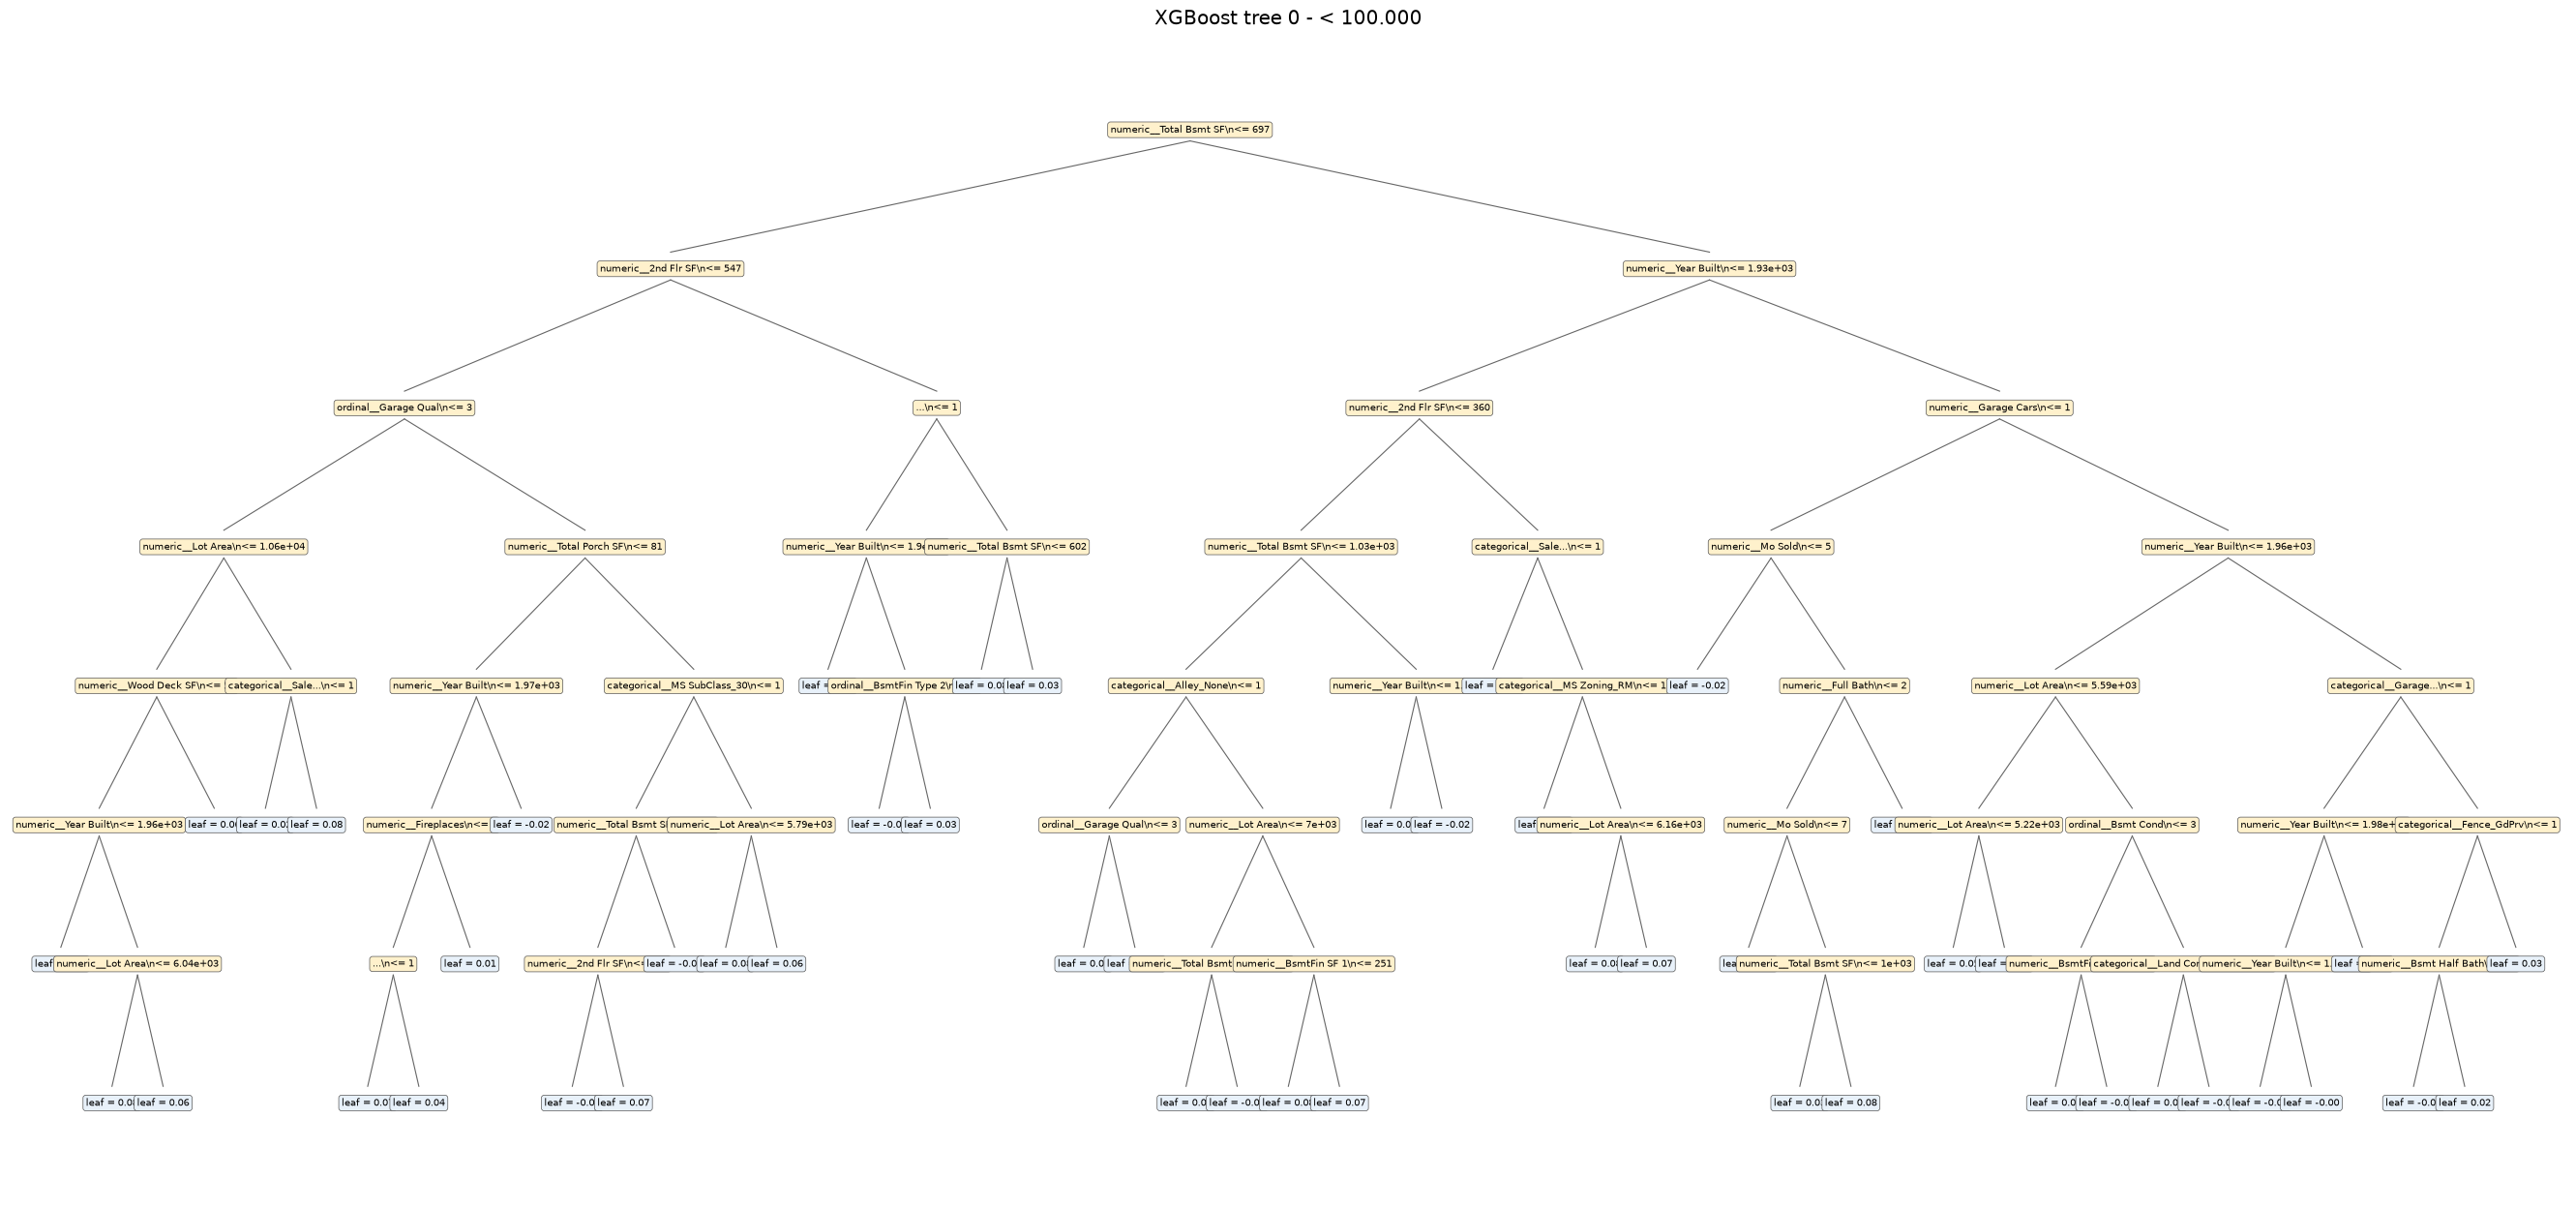

In [22]:
show_tree(0)

#### Highest-total-gain tree


Tree 5; round 0; class >= 400.000; sum of split gains 847.67


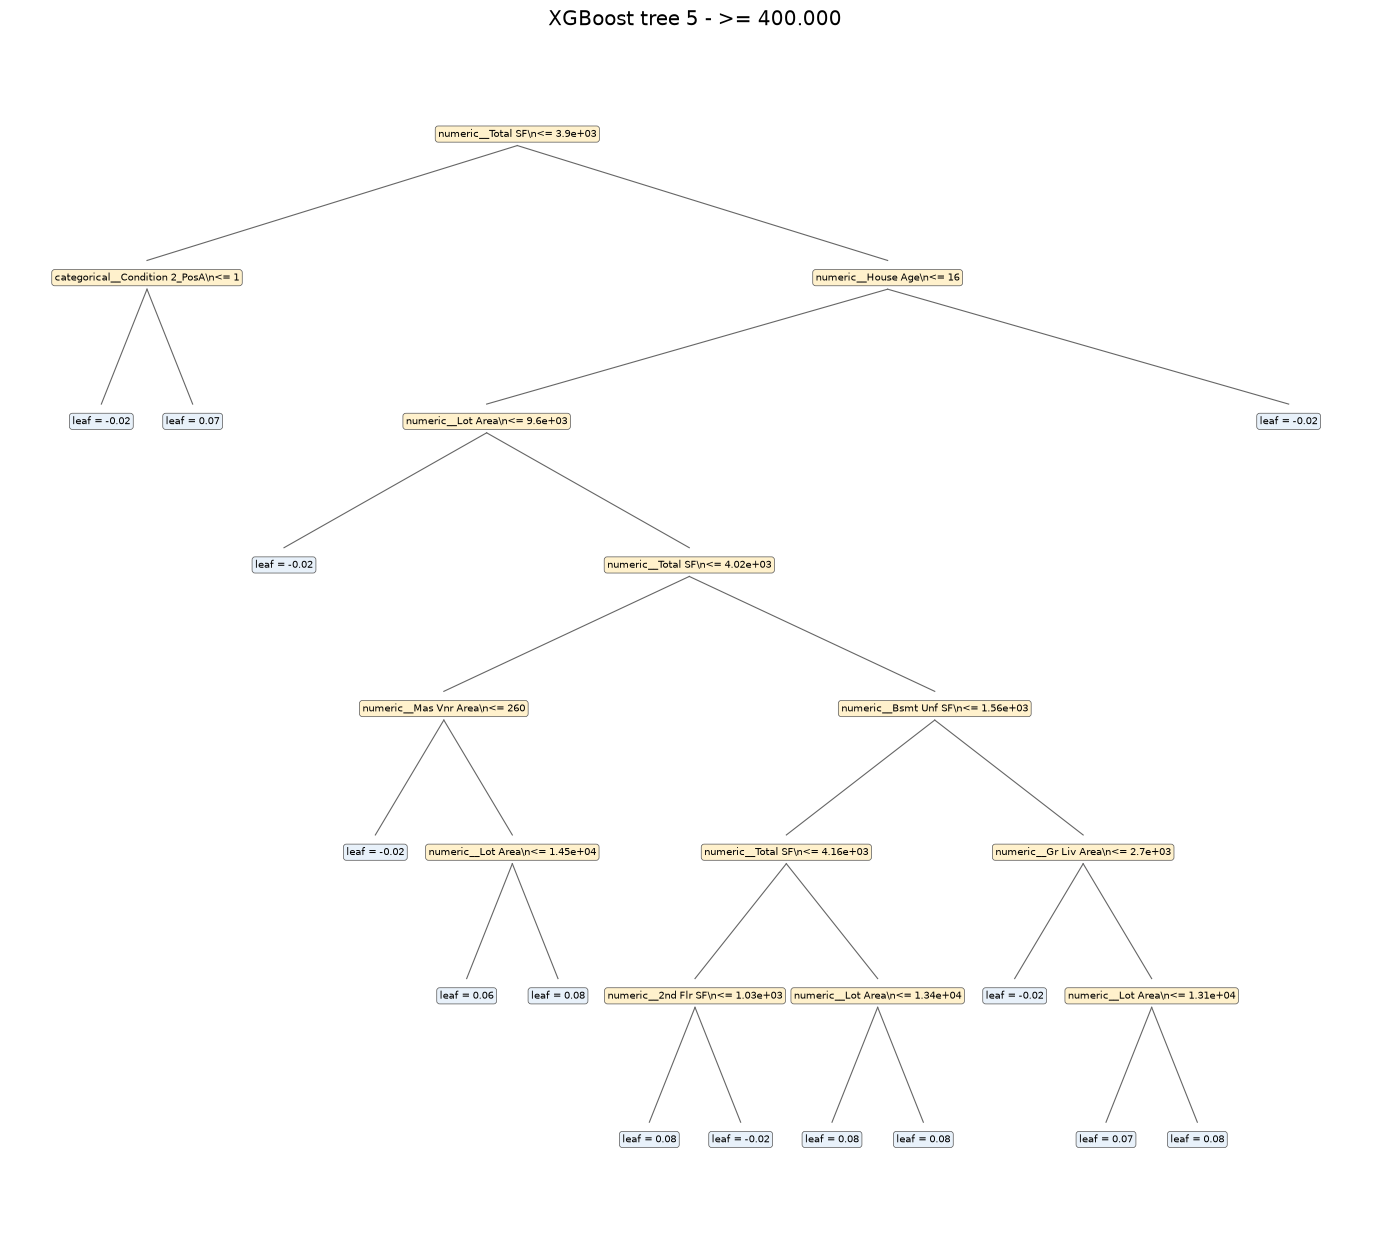

In [23]:
if best_tree_index == 0:
    print("The first tree is also the highest-total-gain tree.")
else:
    show_tree(best_tree_index)

**Interpretation.**
- With `multi:softprob`, XGBoost builds **one tree per class in every round** (6 trees per round). The tree for class $k$ fits the gradient of the loss with respect to that class's score. Tree 0 is therefore round 0 for class < 100,000.
- The tree with the highest total gain is tree 5: also round 0, for class ≥ 400,000. In the first round all predictions start at the same probability ($1/6$), so the gradients and thus the gains are largest. Each later tree only corrects a small residual, scaled by the learning rate (0.028), so the gain per tree falls over the rounds.
- The top splits of both trees use **size** (`Total Bsmt SF`, `2nd Flr SF`, `Total SF`) and **age** (`Year Built`, `House Age`). `Overall Qual` does not appear at the top, because with `colsample_bytree` ≈ 0.44 each tree only sees a random subset of the columns. Single trees are therefore not a reliable view of what matters; the importance plots aggregate over all trees.

### Interpretation
Summarizes the observed holdout results. Feature importance is predictive, not causal.


In [24]:
# Summarize observed test results; feature importance is not causal evidence.
weakest_class = min(
    class_names, key=lambda name: per_class_report[name]["recall"]
)
best_gain_feature = importance["gain"].idxmax()
print("Interpretation:")
print(
    f"- Test accuracy is {accuracy_score(y_test_array, y_pred):.1%}; "
    f"the majority-class baseline is {y_test.value_counts(normalize=True).max():.1%}."
)
print(
    f"- The weakest class by recall is {weakest_class} "
    f"({per_class_report[weakest_class]['recall']:.1%}); see the confusion matrix "
    "for where its errors go."
)
print(
    f"- The highest-gain feature is {best_gain_feature!r}. Gain indicates "
    "predictive split contribution, not a causal effect."
)
print(
    "- ROC and precision-recall curves are one-vs-rest. Cutoffs were selected "
    "from out-of-fold training predictions, then evaluated on the held-out test set."
)


Interpretation:
- Test accuracy is 77.0%; the majority-class baseline is 35.3%.
- The weakest class by recall is >= 400.000 (61.5%); see the confusion matrix for where its errors go.
- The highest-gain feature is 'categorical__MS SubClass_75'. Gain indicates predictive split contribution, not a causal effect.
- ROC and precision-recall curves are one-vs-rest. Cutoffs were selected from out-of-fold training predictions, then evaluated on the held-out test set.


## Conclusion

| | Value (test set, 586 houses) |
|---|---|
| Accuracy | 0.770 (majority baseline 0.353) |
| Macro precision / recall / F1 | 0.746 / 0.738 / 0.741 |
| Weighted F1 | 0.770 |
| CV macro-F1 on training data (stratified 5-fold) | 0.779 |

- **Preparation:** missing values handled by meaning ("not present" → `None` / 0, `Lot Frontage` by neighborhood median inside the pipeline), ordinal encoding for ordered scales, one-hot for nominal features, and a few engineered size and age features.
- **Imbalance:** `balanced` class weights improve the recall of the rare classes; probability thresholds bring no further gain.
- **Bias-variance:** the model is clearly in the high-variance regime (train ≈ 1.0). The best regularization was strong row and column subsampling with many small boosting steps, not L1/L2 penalties.
- **Errors** are almost exclusively between neighboring price classes. The remaining difficulty is the class boundaries, not the model.
- **Evaluation:** with a 586-house test set and 13 houses in the top class, test macro-F1 differences below ≈ 0.02 are not meaningful. CV on the training set is the more reliable basis for comparing models.